# Project N.O.V.A — local Jupyter version

Converted from the Colab notebook so it runs on your own PC (Windows) with **no Google Drive / Colab dependencies**.

**Everything is read from and written to:**
`C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A`

| What | Where it is looked up |
|---|---|
| Dataset subset | `spark_subset_final\` (folder) — or extracted automatically from `spark_subset_final.zip` |
| Detector checkpoint | `best.pt.zip` (Windows shows it as just *best.pt*) |
| Classifier checkpoint | `best_cls.pt.zip` (shown as *best_cls.pt*) |
| **All new output** (YOLO dataset, crops, runs, plots, Module 3 results) | `nova_work\` — created automatically, your original files are never modified |

**Run order:** just run top to bottom. Cells 1–2 are one-time setup.

**GPU note:** if the check in section 2 says `CUDA available: False`, everything still works but training will be slow on CPU. See the note under *Setup* for installing the GPU build of PyTorch.

## 1. Setup (run once)

If you have an **NVIDIA GPU**, install the CUDA build of PyTorch *first* (otherwise `pip install ultralytics` on Windows pulls the CPU-only build). Get the exact command for your CUDA version from https://pytorch.org/get-started/locally/ — it looks like:

```
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124
```

Then run the cell below. Restart the kernel afterwards if it installed anything.

In [1]:
%pip install -q ultralytics pillow matplotlib scikit-learn tqdm ipywidgets

Note: you may need to restart the kernel to use updated packages.


## 2. Paths, settings and helper functions

In [2]:
import os, sys, json, shutil, zipfile, platform
from pathlib import Path

# Anaconda + PyTorch on Windows sometimes crashes with "OMP: Error #15" without this
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import torch
%matplotlib inline

# ═══════════════════════ YOUR SETTINGS ═══════════════════════
BASE_DIR = Path(r"C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A")

RETRAIN_DETECTOR   = False   # False -> reuse your existing best.pt (trained on Colab). True -> train YOLOv8 again
RETRAIN_CLASSIFIER = False   # False -> reuse your existing best_cls.pt. True -> train EfficientNetV2-S again
FORCE_PREPROCESS   = False   # True -> redo the 640x640 resize/normalise step even if it was already done
NUM_WORKERS        = 0       # DataLoader workers. 0 is the safe choice on Windows + Jupyter
# ═════════════════════════════════════════════════════════════

WORK_DIR = BASE_DIR / "nova_work"          # every new file goes here
YOLO_DIR = WORK_DIR / "nova_yolo"          # YOLO-format dataset
CLS_DIR  = WORK_DIR / "nova_cls"           # cropped images for the classifier
RUNS_DIR = WORK_DIR / "runs"               # YOLO training / validation runs
OUT_DIR  = WORK_DIR / "module3_outputs"    # Module 3 results
for d in (WORK_DIR, YOLO_DIR, CLS_DIR, RUNS_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)                         # so downloaded weights (yolov8s.pt) and stray files land here

DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"
YOLO_DEVICE = 0 if torch.cuda.is_available() else "cpu"

assert BASE_DIR.is_dir(), f"Folder not found: {BASE_DIR}"


# ───────────────────────── helpers ─────────────────────────
def _has_splits(d):
    return d.is_dir() and all((d / s).is_dir() for s in ("train", "val", "test"))

def _search_splits(root, max_depth=2):
    """Return the folder (root or a sub-folder up to max_depth) that directly contains train/ val/ test/."""
    if _has_splits(root):
        return root
    if max_depth == 0 or not root.is_dir():
        return None
    for child in sorted(p for p in root.iterdir() if p.is_dir()):
        found = _search_splits(child, max_depth - 1)
        if found:
            return found
    return None

def find_dataset_root(base):
    """Locate the dataset folder (train/val/test). Extracts spark_subset_final.zip if no folder is usable."""
    for name in ("spark_subset_final", "spark_subset"):
        found = _search_splits(base / name)
        if found:
            return found
    zip_path = base / "spark_subset_final.zip"
    if zip_path.is_file():
        target = WORK_DIR / "spark_subset_extracted"
        if not _search_splits(target):
            print(f"Extracting {zip_path.name} -> {target} (one time, ~400 MB) ...")
            with zipfile.ZipFile(zip_path) as z:
                z.extractall(target)
        found = _search_splits(target)
        if found:
            return found
    raise FileNotFoundError(
        "Could not find the dataset. Expected a folder containing train/ val/ test/ inside "
        f"'{base / 'spark_subset_final'}' (or spark_subset_final.zip). Folder contains: "
        f"{[p.name for p in base.iterdir()]}")

def resolve_checkpoint(base, name, out_dir):
    """
    Return a ready-to-load .pt file for `name` (e.g. 'best.pt'), or None if not found.
    Handles: a real best.pt file, best.pt.zip (a renamed checkpoint, like the Colab version used),
    a .zip that wraps a .pt file, or a folder that holds a .pt file.
    """
    out = out_dir / f"{Path(name).stem}_ready.pt"
    candidates = [base / name, base / (name + ".zip")]
    for p in candidates:
        if not p.is_file():
            continue
        if zipfile.is_zipfile(p):
            with zipfile.ZipFile(p) as z:
                wrapped = [n for n in z.namelist() if n.lower().endswith(".pt")]
                if wrapped:                                   # a zip that contains a .pt file
                    with z.open(wrapped[0]) as src_f, open(out, "wb") as dst_f:
                        shutil.copyfileobj(src_f, dst_f)
                    return out
        shutil.copyfile(p, out)                               # PyTorch checkpoints are zip files already: just copy
        return out
    folder = base / name
    if folder.is_dir():                                       # e.g. an extracted folder that contains the .pt file
        pts = sorted(folder.rglob("*.pt"), key=lambda q: q.stat().st_size, reverse=True)
        if pts:
            shutil.copyfile(pts[0], out)
            return out
    return None


DATA_ROOT       = find_dataset_root(BASE_DIR)
DETECTOR_PATH   = resolve_checkpoint(BASE_DIR, "best.pt", WORK_DIR)       # YOLO detector from Colab
CLASSIFIER_PATH = resolve_checkpoint(BASE_DIR, "best_cls.pt", WORK_DIR)   # EfficientNetV2-S from Colab

print("Python        :", sys.version.split()[0], "|", platform.system())
print("PyTorch       :", torch.__version__)
print("CUDA available:", torch.cuda.is_available(), "->", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "running on CPU")
print()
print("BASE_DIR      :", BASE_DIR)
print("DATA_ROOT     :", DATA_ROOT)
print("Detector ckpt :", DETECTOR_PATH or "NOT FOUND (detector will be trained)")
print("Classifier ckpt:", CLASSIFIER_PATH or "NOT FOUND (classifier will be trained)")
print("Output folder :", WORK_DIR)
total, used, free = shutil.disk_usage(WORK_DIR)
print(f"Disk free on that drive: {free / 1e9:.1f} GB")

Python        : 3.12.15 | Windows
PyTorch       : 2.14.1+cpu
CUDA available: False -> running on CPU

BASE_DIR      : C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A
DATA_ROOT     : C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\spark_subset_final
Detector ckpt : C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\best_ready.pt
Classifier ckpt: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\best_cls_ready.pt
Output folder : C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work
Disk free on that drive: 5.6 GB


## 3. Dataset check and preprocessing
Bounding-box sanity check on a few random images (green box = ground truth).

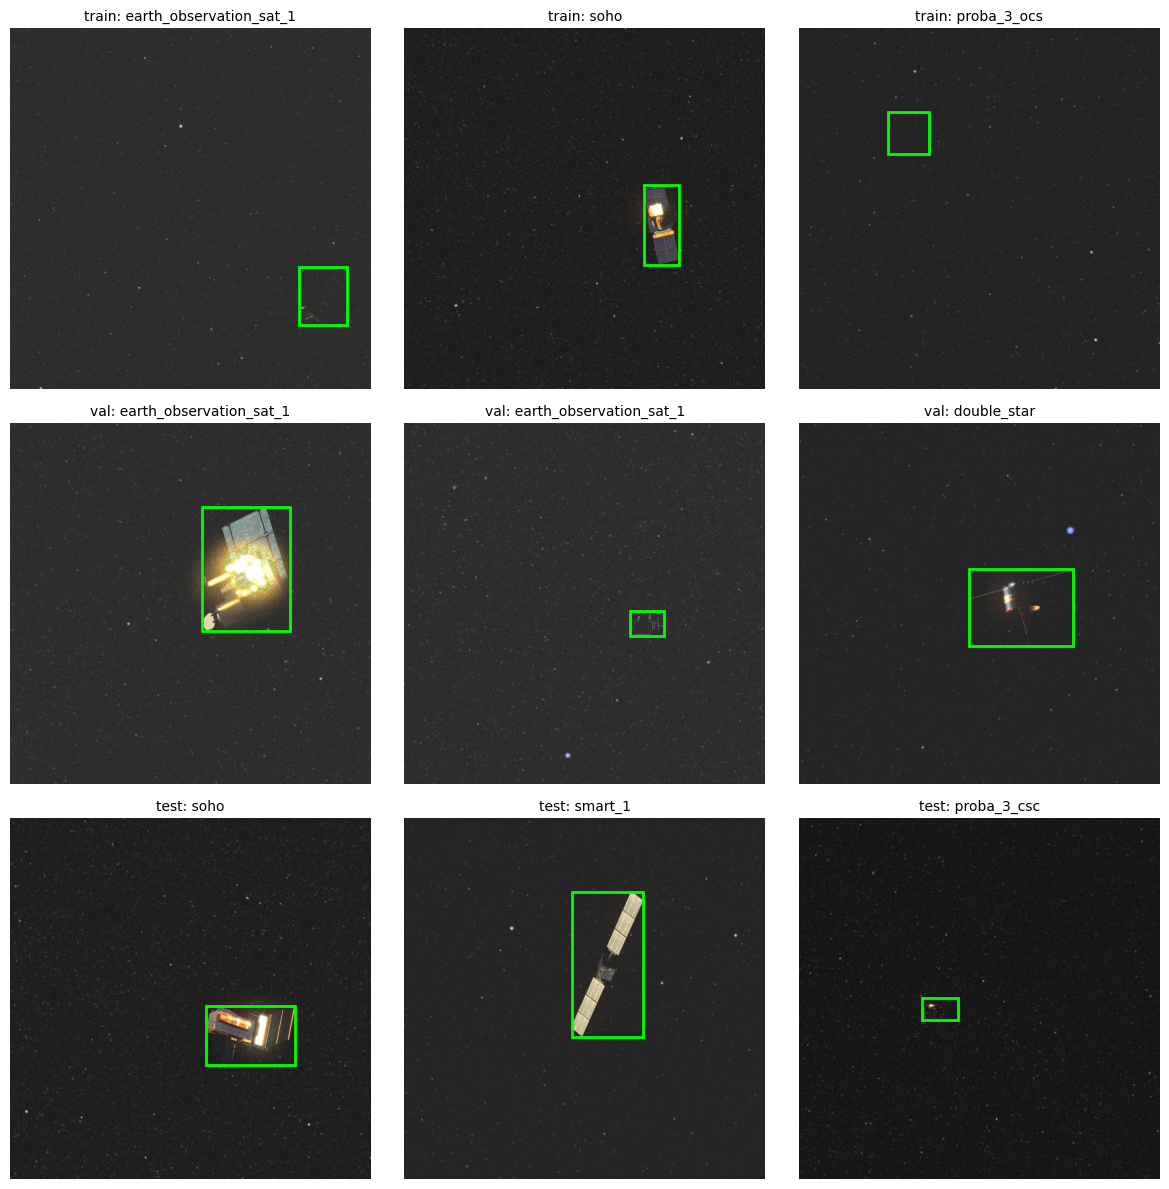

Saved to C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\bbox_sanity_check.png


In [3]:
import json
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from pathlib import Path

OUT_ROOT = DATA_ROOT

SAMPLES_PER_SPLIT = 3

def load_jsonl(path):
    records = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line)
            records[rec["filename"]] = rec
    return records

fig, axes = plt.subplots(3, SAMPLES_PER_SPLIT, figsize=(4 * SAMPLES_PER_SPLIT, 12))

for row, split in enumerate(["train", "val", "test"]):
    labels_path = OUT_ROOT / split / "labels.jsonl"
    images_dir = OUT_ROOT / split / "images"
    records = load_jsonl(labels_path)

    sample_files = random.sample(list(records.keys()), SAMPLES_PER_SPLIT)

    for col, fname in enumerate(sample_files):
        ax = axes[row][col]
        rec = records[fname]
        img_path = images_dir / fname

        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)

        xmin, ymin, xmax, ymax = rec["bbox"]
        rect = Rectangle(
            (xmin, ymin), xmax - xmin, ymax - ymin,
            linewidth=2, edgecolor="lime", facecolor="none"
        )
        ax.add_patch(rect)
        ax.set_title(f"{split}: {rec['class']}", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.savefig(WORK_DIR / "bbox_sanity_check.png", dpi=100)
plt.show()
print("Saved to", WORK_DIR / "bbox_sanity_check.png")

Resize every image to 640×640 and rescale its box. This was already done once, so it is **skipped automatically** if `images_processed/` and `labels_processed.jsonl` exist (set `FORCE_PREPROCESS = True` above to redo it).

In [4]:
import json
import numpy as np
from PIL import Image
from pathlib import Path

OUT_ROOT = DATA_ROOT
TARGET_SIZE = (640, 640)   # match your detection model's input (YOLOv8/HT-LCNN)

for split in ["train", "val", "test"]:
    images_dir = OUT_ROOT / split / "images"
    labels_path = OUT_ROOT / split / "labels.jsonl"
    processed_dir = OUT_ROOT / split / "images_processed"
    processed_dir.mkdir(exist_ok=True)

    already_done = (OUT_ROOT / split / "labels_processed.jsonl").is_file() and any(processed_dir.glob("*.jpg"))
    if already_done and not FORCE_PREPROCESS:
        print(f"{split}: already preprocessed -> skipping")
        continue

    records = []
    with open(labels_path, encoding="utf-8") as f:
        for line in f:
            records.append(json.loads(line))

    new_records = []
    for rec in records:
        img_path = images_dir / rec["filename"]
        img = Image.open(img_path).convert("RGB")
        orig_w, orig_h = img.size

        img_resized = img.resize(TARGET_SIZE, Image.BILINEAR)
        scale_x, scale_y = TARGET_SIZE[0] / orig_w, TARGET_SIZE[1] / orig_h

        # normalize to [0,1] and save as .npy (keeps normalized floats, not just resized jpg)
        arr = np.asarray(img_resized).astype(np.float32) / 255.0
        np.save(processed_dir / f"{Path(rec['filename']).stem}.npy", arr)

        # also save a viewable resized jpg (handy for the sanity checks / PPT)
        img_resized.save(processed_dir / rec["filename"])

        xmin, ymin, xmax, ymax = rec["bbox"]
        new_bbox = [xmin * scale_x, ymin * scale_y, xmax * scale_x, ymax * scale_y]

        new_records.append({
            "filename": rec["filename"],
            "class": rec["class"],
            "bbox": new_bbox,
            "orig_size": [orig_w, orig_h]
        })

    with open(OUT_ROOT / split / "labels_processed.jsonl", "w", encoding="utf-8") as f:
        for r in new_records:
            f.write(json.dumps(r) + "\n")

    print(f"{split}: {len(new_records)} images resized + normalized -> {processed_dir}")

print("\nDone. Each split now has images_processed/ (resized jpgs + normalized .npy arrays) and labels_processed.jsonl (rescaled bboxes).")

train: already preprocessed -> skipping
val: already preprocessed -> skipping
test: already preprocessed -> skipping

Done. Each split now has images_processed/ (resized jpgs + normalized .npy arrays) and labels_processed.jsonl (rescaled bboxes).


## 4. Module 1 — YOLOv8 object detector

In [5]:
# Verify the detector checkpoint loads and the dataset folders are present
from ultralytics import YOLO

if DETECTOR_PATH is not None:
    _det = YOLO(str(DETECTOR_PATH))
    print("Detector loaded successfully:", _det.task)
    del _det
else:
    print("No existing detector found -> it will be trained in the next cells.")

for split in ["train", "val", "test"]:
    folder = DATA_ROOT / split
    print(split, "exists:", folder.is_dir())
    if folder.is_dir():
        print("  Contents:", sorted(p.name for p in folder.iterdir()))

Detector loaded successfully: detect
train exists: True
  Contents: ['images', 'images_processed', 'labels.jsonl', 'labels_processed.jsonl']
val exists: True
  Contents: ['images', 'images_processed', 'labels.jsonl', 'labels_processed.jsonl']
test exists: True
  Contents: ['images', 'images_processed', 'labels.jsonl', 'labels_processed.jsonl']


Convert the dataset to YOLO format (images + one `.txt` label per image) and write `data.yaml`.

In [6]:
import json, shutil
from pathlib import Path

SRC = DATA_ROOT
DST = YOLO_DIR
IMG_SIZE = 640

for split in ["train", "val", "test"]:
    (DST / "images" / split).mkdir(parents=True, exist_ok=True)
    (DST / "labels" / split).mkdir(parents=True, exist_ok=True)

    with open(SRC / split / "labels_processed.jsonl", encoding="utf-8") as f:
        records = [json.loads(line) for line in f]

    for rec in records:
        fname = rec["filename"]
        shutil.copy(SRC / split / "images_processed" / fname,
                    DST / "images" / split / fname)

        xmin, ymin, xmax, ymax = rec["bbox"]
        # clip to image bounds, just in case
        xmin, xmax = max(0, xmin), min(IMG_SIZE, xmax)
        ymin, ymax = max(0, ymin), min(IMG_SIZE, ymax)

        xc = ((xmin + xmax) / 2) / IMG_SIZE
        yc = ((ymin + ymax) / 2) / IMG_SIZE
        w = (xmax - xmin) / IMG_SIZE
        h = (ymax - ymin) / IMG_SIZE

        with open(DST / "labels" / split / f"{Path(fname).stem}.txt", "w") as lf:
            lf.write(f"0 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")

# dataset config file that YOLO reads (forward slashes so Windows paths are safe in YAML)
yaml_text = f"""path: {DST.as_posix()}
train: images/train
val: images/val
test: images/test
names:
  0: object
"""
with open(DST / "data.yaml", "w") as f:
    f.write(yaml_text)

# sanity check
for split in ["train", "val", "test"]:
    n_img = len(list((DST / "images" / split).glob("*.jpg")))
    n_lbl = len(list((DST / "labels" / split).glob("*.txt")))
    print(f"{split}: {n_img} images, {n_lbl} labels")

print("\nSample label:")
sample = next((DST / "labels" / "train").glob("*.txt"))
print(sample.name, "->", sample.read_text())

train: 300 images, 300 labels
val: 100 images, 100 labels
test: 100 images, 100 labels

Sample label:
img000750.txt -> 0 0.581543 0.570312 0.688477 0.779297



### Train the detector (optional)
With `RETRAIN_DETECTOR = False` (default) this cell is skipped and your existing `best.pt` is used. Set it to `True` in section 2 to train again (50 epochs, early stopping after 15 without improvement). If you run out of GPU memory, lower `batch` to 8.

In [7]:
from ultralytics import YOLO

if RETRAIN_DETECTOR or DETECTOR_PATH is None:
    # pretrained on COCO, will be fine-tuned on our 300 images (weights download automatically the first time)
    model = YOLO("yolov8s.pt")

    results = model.train(
        data=str(YOLO_DIR / "data.yaml"),
        epochs=50,
        imgsz=640,
        batch=16,
        patience=15,          # stop early if val metrics stop improving
        project=str(RUNS_DIR),
        name="nova_det",
        exist_ok=True,        # re-running overwrites instead of creating nova_det2, nova_det3 ...
        seed=42,
        workers=NUM_WORKERS,
        device=YOLO_DEVICE,
    )
    DET_WEIGHTS = Path(results.save_dir) / "weights" / "best.pt"
    if DETECTOR_PATH is None:
        DETECTOR_PATH = DET_WEIGHTS           # Module 3 will use the freshly trained detector
else:
    DET_WEIGHTS = DETECTOR_PATH
    print("Skipping detector training, using existing checkpoint:", DET_WEIGHTS)

print("Detector weights in use:", DET_WEIGHTS)

Skipping detector training, using existing checkpoint: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\best_ready.pt
Detector weights in use: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\best_ready.pt


### Evaluate the detector on the test split (mAP + IoU)

In [8]:
from ultralytics import YOLO
import numpy as np
from pathlib import Path

model = YOLO(str(DET_WEIGHTS))

# ---- 1. mAP on the test split ----
metrics = model.val(data=str(YOLO_DIR / "data.yaml"), split="test", imgsz=640,
                    workers=NUM_WORKERS, device=YOLO_DEVICE, project=str(RUNS_DIR), name="test_eval", exist_ok=True)
print("\n=== TEST SET: mAP ===")
print(f"Precision : {metrics.box.mp:.3f}")
print(f"Recall    : {metrics.box.mr:.3f}")
print(f"mAP50     : {metrics.box.map50:.3f}")
print(f"mAP50-95  : {metrics.box.map:.3f}")

# ---- 2. Mean IoU (top-confidence prediction vs ground truth, per image) ----
def iou_xyxy(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

img_dir = YOLO_DIR / "images" / "test"
lbl_dir = YOLO_DIR / "labels" / "test"
S = 640

ious, missed = [], 0
for img_path in sorted(img_dir.glob("*.jpg")):
    xc, yc, w, h = map(float, (lbl_dir / f"{img_path.stem}.txt").read_text().split()[1:5])
    gt = [(xc - w/2) * S, (yc - h/2) * S, (xc + w/2) * S, (yc + h/2) * S]

    res = model.predict(img_path, imgsz=640, conf=0.25, verbose=False)[0]
    if len(res.boxes) == 0:
        ious.append(0.0)
        missed += 1
        continue
    best = res.boxes.conf.argmax()
    pred = res.boxes.xyxy[best].cpu().numpy()
    ious.append(iou_xyxy(pred, gt))

ious = np.array(ious)
detected = ious[ious > 0]
print("\n=== TEST SET: IoU ===")
N_TEST = len(ious)
print(f"Mean IoU (all {N_TEST} images, misses count as 0): {ious.mean():.3f}")
print(f"Mean IoU (detected images only)             : {detected.mean() if len(detected) else float('nan'):.3f}")
print(f"Images with no prediction                   : {missed}/{N_TEST}")
print(f"Images with IoU > 0.5                       : {(ious > 0.5).sum()}/{N_TEST}")

Ultralytics 8.4.177  Python-3.12.15 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-1355U)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 3.2±0.6 MB/s, size: 36.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\nova_yolo\labels\test... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 541.2it/s 0.2s3s
val: New cache created: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\nova_yolo\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.0s/it 20.9s3.8ss
                   all        100        100      0.761       0.67      0.733       0.44
Speed: 2.3ms preprocess, 192.5ms inference, 0.0ms loss, 1.0ms postprocess per

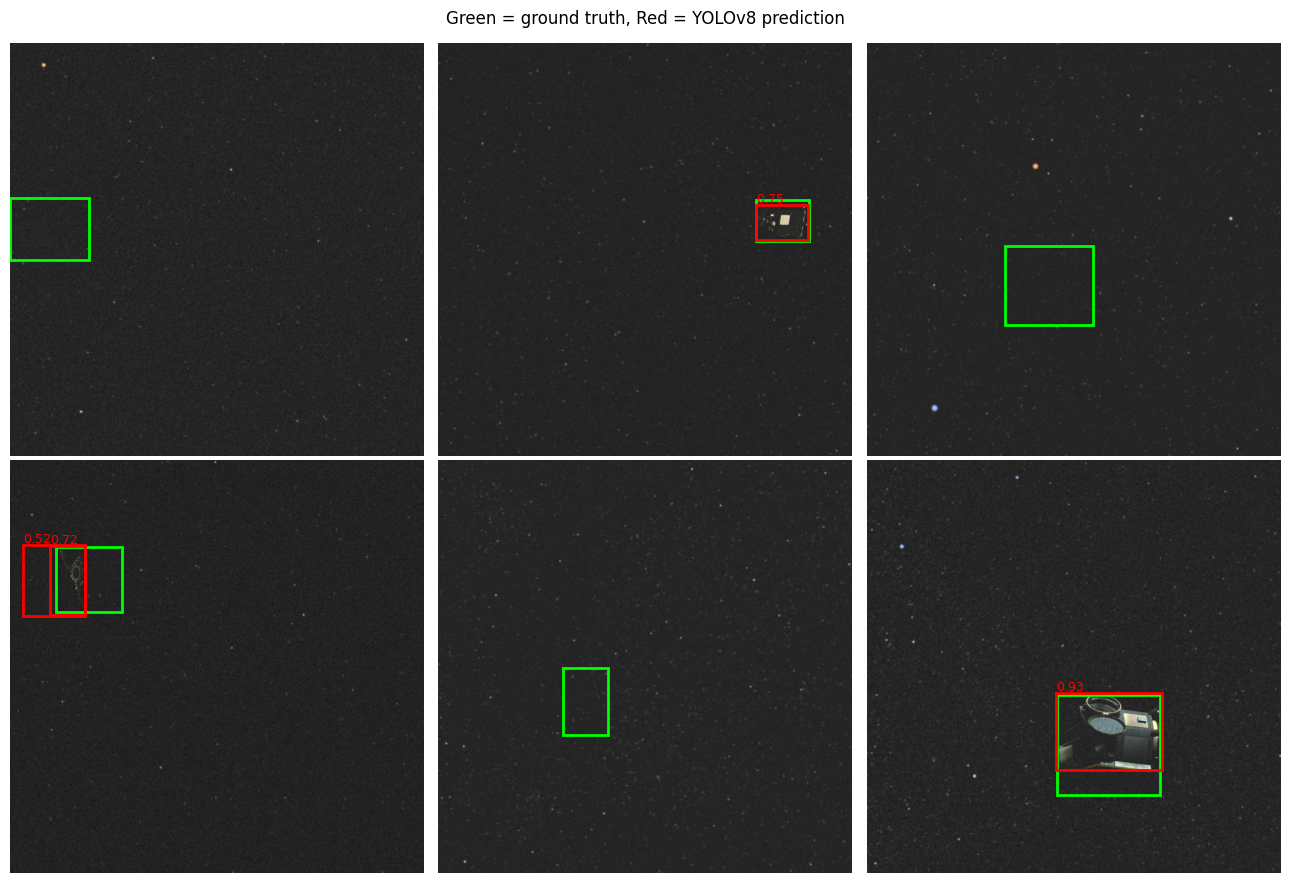

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import random

random.seed(1)
files = random.sample(sorted(img_dir.glob("*.jpg")), 6)

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, p in zip(axes.flat, files):
    xc, yc, w, h = map(float, (lbl_dir / f"{p.stem}.txt").read_text().split()[1:5])
    gx1, gy1 = (xc - w/2) * S, (yc - h/2) * S
    ax.imshow(Image.open(p))
    ax.add_patch(Rectangle((gx1, gy1), w * S, h * S, fill=False, edgecolor="lime", linewidth=2))

    res = model.predict(p, imgsz=640, conf=0.25, verbose=False)[0]
    for b, c in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy()):
        ax.add_patch(Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, edgecolor="red", linewidth=2))
        ax.text(b[0], b[1] - 4, f"{c:.2f}", color="red", fontsize=9)
    ax.axis("off")

plt.suptitle("Green = ground truth, Red = YOLOv8 prediction")
plt.tight_layout()
plt.savefig(WORK_DIR / "test_predictions.png", dpi=100)
plt.show()

## 5. Module 2 — EfficientNetV2-S classifier
Crop each object (with 10% padding) into one folder per class.

In [10]:
#Cell 13:
import json
from pathlib import Path
from PIL import Image
from collections import Counter

SRC = DATA_ROOT
DST = CLS_DIR
PAD = 0.10

for split in ["train", "val", "test"]:
    with open(SRC / split / "labels_processed.jsonl", encoding="utf-8") as f:
        records = [json.loads(line) for line in f]

    counts = Counter()
    for rec in records:
        cls = rec["class"]
        (DST / split / cls).mkdir(parents=True, exist_ok=True)

        img = Image.open(SRC / split / "images_processed" / rec["filename"]).convert("RGB")
        x1, y1, x2, y2 = rec["bbox"]
        w, h = x2 - x1, y2 - y1
        x1, y1 = max(0, x1 - PAD * w), max(0, y1 - PAD * h)
        x2, y2 = min(640, x2 + PAD * w), min(640, y2 + PAD * h)

        img.crop((int(x1), int(y1), int(x2), int(y2))).save(DST / split / cls / rec["filename"])
        counts[cls] += 1

    print(f"\n{split} ({sum(counts.values())} crops):")
    for cls, n in sorted(counts.items()):
        print(f"  {cls}: {n}")


train (300 crops):
  cheops: 27
  debris: 27
  double_star: 28
  earth_observation_sat_1: 27
  lisa_pathfinder: 27
  proba_2: 27
  proba_3_csc: 27
  proba_3_ocs: 27
  smart_1: 28
  soho: 28
  xmm_newton: 27

val (100 crops):
  cheops: 9
  debris: 9
  double_star: 9
  earth_observation_sat_1: 9
  lisa_pathfinder: 10
  proba_2: 9
  proba_3_csc: 9
  proba_3_ocs: 9
  smart_1: 9
  soho: 9
  xmm_newton: 9

test (100 crops):
  cheops: 9
  debris: 9
  double_star: 9
  earth_observation_sat_1: 9
  lisa_pathfinder: 9
  proba_2: 9
  proba_3_csc: 10
  proba_3_ocs: 9
  smart_1: 9
  soho: 9
  xmm_newton: 9


### Train (or load) the classifier
With `RETRAIN_CLASSIFIER = False` (default) the training loop is skipped and your existing `best_cls.pt` is loaded in the evaluation cell. Set it to `True` in section 2 to train again (30 epochs; downloads the ImageNet weights the first time).

In [11]:
#Cell 14:
import torch, torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from PIL import ImageOps

device = DEVICE
SIZE = 224
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def pad_square(img):
    return ImageOps.pad(img, (SIZE, SIZE), color=(0, 0, 0))

train_tf = transforms.Compose([
    transforms.Lambda(pad_square),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Lambda(pad_square),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

root = str(CLS_DIR)
train_ds = datasets.ImageFolder(f"{root}/train", train_tf)
val_ds   = datasets.ImageFolder(f"{root}/val", eval_tf)
test_ds  = datasets.ImageFolder(f"{root}/test", eval_tf)
class_names = train_ds.classes
print(class_names)

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=NUM_WORKERS)
val_dl   = DataLoader(val_ds, batch_size=32, num_workers=NUM_WORKERS)
test_dl  = DataLoader(test_ds, batch_size=32, num_workers=NUM_WORKERS)

TRAIN_CLS = RETRAIN_CLASSIFIER or CLASSIFIER_PATH is None
CLS_CKPT = WORK_DIR / "best_cls.pt" if TRAIN_CLS else CLASSIFIER_PATH

# EfficientNetV2-S, new head sized to the number of classes
# (ImageNet weights are only needed when training; an existing checkpoint replaces them anyway)
model = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1 if TRAIN_CLS else None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
model = model.to(device)

EPOCHS = 30
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def evaluate(dl):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
            total += y.size(0)
    return correct / total

if TRAIN_CLS:
    best_val = 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        run_loss = correct = total = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
        scheduler.step()

        val_acc = evaluate(val_dl)
        print(f"Epoch {epoch:2d}/{EPOCHS} | loss {run_loss/total:.3f} | train acc {correct/total:.3f} | val acc {val_acc:.3f}")

        if val_acc > best_val:
            best_val = val_acc
            torch.save(model.state_dict(), CLS_CKPT)

    print(f"\nBest val accuracy: {best_val:.3f}")
else:
    print("Skipping classifier training, will load existing checkpoint:", CLS_CKPT)

['cheops', 'debris', 'double_star', 'earth_observation_sat_1', 'lisa_pathfinder', 'proba_2', 'proba_3_csc', 'proba_3_ocs', 'smart_1', 'soho', 'xmm_newton']
Skipping classifier training, will load existing checkpoint: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\best_cls_ready.pt


### Evaluate the classifier on the test split

=== TEST ACCURACY: 0.830 ===

                          precision    recall  f1-score   support
cheops                        1.000     1.000     1.000         9
debris                        0.889     0.889     0.889         9
double_star                   1.000     0.778     0.875         9
earth_observation_sat_1       0.571     0.889     0.696         9
lisa_pathfinder               1.000     0.889     0.941         9
proba_2                       0.889     0.889     0.889         9
proba_3_csc                   1.000     0.700     0.824        10
proba_3_ocs                   0.700     0.778     0.737         9
smart_1                       0.800     0.889     0.842         9
soho                          0.750     1.000     0.857         9
xmm_newton                    0.800     0.444     0.571         9

accuracy                                          0.830       100
macro avg                     0.854     0.831     0.829       100
weighted avg                  0.856     0.830

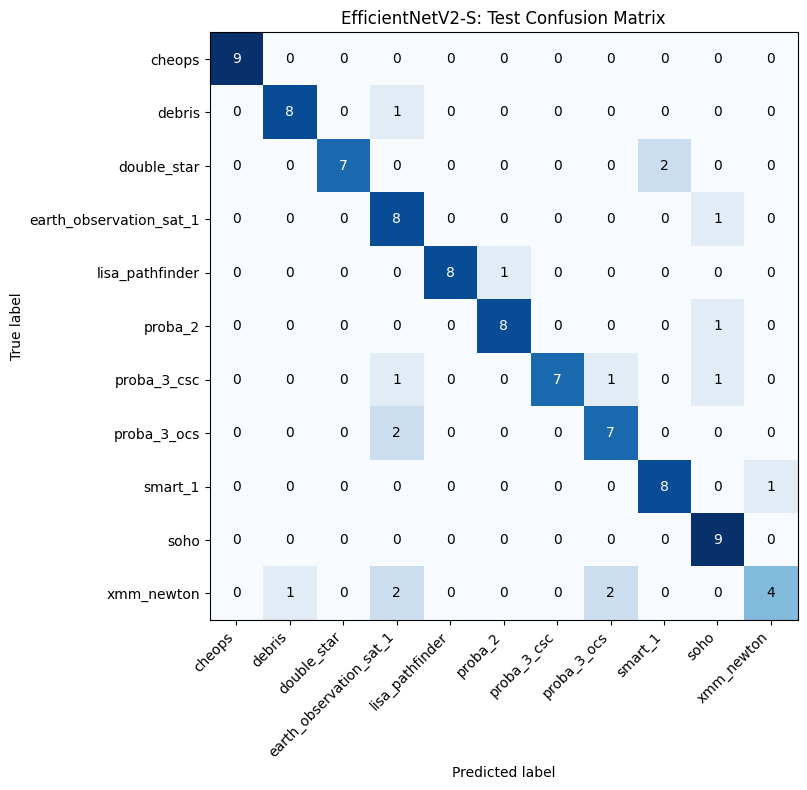

Saved confusion matrix to C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\confusion_matrix.png


In [12]:
#Cell 15:
import numpy as np
import matplotlib.pyplot as plt

model.load_state_dict(torch.load(CLS_CKPT, map_location=device))
model.eval()

preds, labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        preds.extend(model(x.to(device)).argmax(1).cpu().numpy())
        labels.extend(y.numpy())
preds, labels = np.array(preds), np.array(labels)

print(f"=== TEST ACCURACY: {(preds == labels).mean():.3f} ===\n")

# ---- confusion matrix (rows = true class, columns = predicted class) ----
n = len(class_names)
cm = np.zeros((n, n), dtype=int)
for t, p in zip(labels, preds):
    cm[t, p] += 1

# ---- per-class precision / recall / F1 ----
tp = np.diag(cm).astype(float)
support = cm.sum(axis=1)            # true samples per class
pred_count = cm.sum(axis=0)         # predicted samples per class
precision = np.divide(tp, pred_count, out=np.zeros(n), where=pred_count > 0)
recall    = np.divide(tp, support,    out=np.zeros(n), where=support > 0)
denom     = precision + recall
f1        = np.divide(2 * precision * recall, denom, out=np.zeros(n), where=denom > 0)

width = max(12, max(len(c) for c in class_names) + 2)
print(f"{'':{width}s}{'precision':>10s}{'recall':>10s}{'f1-score':>10s}{'support':>10s}")
for i, name in enumerate(class_names):
    print(f"{name:{width}s}{precision[i]:10.3f}{recall[i]:10.3f}{f1[i]:10.3f}{support[i]:10d}")
print()
total = support.sum()
print(f"{'accuracy':{width}s}{'':10s}{'':10s}{(preds == labels).mean():10.3f}{total:10d}")
print(f"{'macro avg':{width}s}{precision.mean():10.3f}{recall.mean():10.3f}{f1.mean():10.3f}{total:10d}")
w = support / total
print(f"{'weighted avg':{width}s}{(precision * w).sum():10.3f}{(recall * w).sum():10.3f}{(f1 * w).sum():10.3f}{total:10d}")

# ---- plot the confusion matrix ----
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(n)); ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(n)); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
thresh = cm.max() / 2 if cm.max() > 0 else 0
for i in range(n):
    for j in range(n):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")
plt.title("EfficientNetV2-S: Test Confusion Matrix")
plt.tight_layout()
plt.savefig(WORK_DIR / "confusion_matrix.png", dpi=100)
plt.show()

print("Saved confusion matrix to", WORK_DIR / "confusion_matrix.png")

## 6. Module 3 — Tracking (Kalman / UKF / LSTM)
Uses your trained detector (`best.pt`) on simulated motion sequences built from the **val** and **test** images.
By default `MAX_IMAGES = 10` (quick test) — set it to `None` in the settings cell below for the full run.

In [13]:
# Module 3 setup check
required_files = {
    "YOLO detector": DETECTOR_PATH,
    "Dataset folder": DATA_ROOT,
}
for name, path in required_files.items():
    ok = path is not None and Path(path).exists()
    print(f"{'FOUND' if ok else 'MISSING':8} {name}: {path}")
assert all(p is not None and Path(p).exists() for p in required_files.values()), \
    "Required file(s) missing. Check the paths printed above."

print("\nModule 3 output folder:", OUT_DIR)
print("Module 3 setup checks passed!")

FOUND    YOLO detector: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\best_ready.pt
FOUND    Dataset folder: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\spark_subset_final

Module 3 output folder: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module3_outputs
Module 3 setup checks passed!


In [14]:
import json, math, pickle, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn

device = DEVICE
print("Running on:", device, "(if this says cpu and you have an NVIDIA GPU, install the CUDA build of PyTorch - see Setup)")

Running on: cpu (if this says cpu and you have an NVIDIA GPU, install the CUDA build of PyTorch - see Setup)


In [15]:
# Load the val/test images and labels (already extracted on disk, nothing to unzip)
ROOT = str(DATA_ROOT)

def load_split(split):
    with open(f"{ROOT}/{split}/labels_processed.jsonl", encoding="utf-8") as f:
        recs = [json.loads(line) for line in f]
    for r in recs:
        r["path"] = f"{ROOT}/{split}/images_processed/{r['filename']}"
    return recs

dev_recs  = load_split("val")    # used to tune the trackers and train the LSTM
test_recs = load_split("test")   # used only for the final scores
print(f"dev (val) images: {len(dev_recs)}   test images: {len(test_recs)}")
print("example record:", {k: dev_recs[0][k] for k in ("filename", "class", "bbox")})

dev (val) images: 100   test images: 100
example record: {'filename': 'img087910.jpg', 'class': 'smart_1', 'bbox': [233.75, 182.5, 345.625, 265.0]}


In [16]:
from ultralytics import YOLO
detector = YOLO(str(DETECTOR_PATH))

def detect_frames(frames_rgb):
    """frames_rgb: list of HxWx3 uint8 RGB arrays -> array (N, 5): cx, cy, w, h, conf (NaN if nothing found)."""
    frames_bgr = [f[:, :, ::-1].copy() for f in frames_rgb]
    results = detector.predict(frames_bgr, imgsz=640, conf=0.25, verbose=False, device=YOLO_DEVICE)
    out = np.full((len(results), 5), np.nan)
    for i, r in enumerate(results):
        if len(r.boxes) == 0:
            continue
        j = int(r.boxes.conf.argmax())                  # keep only the most confident box
        x1, y1, x2, y2 = r.boxes.xyxy[j].cpu().numpy()
        out[i] = [(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1, float(r.boxes.conf[j])]
    return out

# quick sanity test on 20 val images
found, errs = 0, []
for rec in dev_recs[:20]:
    img = np.array(Image.open(rec["path"]).convert("RGB"))
    d = detect_frames([img])[0]
    gx, gy = (rec["bbox"][0] + rec["bbox"][2]) / 2, (rec["bbox"][1] + rec["bbox"][3]) / 2
    if not np.isnan(d[0]):
        found += 1
        errs.append(math.hypot(d[0] - gx, d[1] - gy))
print(f"detector found the object in {found}/20 images")
print(f"average centre error when found: {np.mean(errs):.1f} pixels")

detector found the object in 19/20 images
average centre error when found: 9.4 pixels


In [17]:
#Setting up motion assumptions and tracking thresholds
RNG_SEED        = 42
IMG_W = IMG_H   = 640
SEQ_LEN         = 30                     # frames per sequence
SPEED_RANGE     = (2.0, 8.0)             # pixels per frame
TURN_RATE_RANGE = (0.02, 0.06)           # radians per frame (curved paths)
DEV_KINDS       = ["linear", "curved"]                 # normal motion, for tuning/training
TEST_KINDS      = ["linear", "curved", "maneuver"]     # "maneuver" = sudden turn, kept for Module 4
GATE_D2         = 13.8                   # reject detections that are wildly off (see Step 8)
MAX_SPEED       = 1.5 * SPEED_RANGE[1]   # px/frame. A faster jump between two detections means one is a false alarm
LOST_AFTER      = 3                      # after this many rejected detections in a row, restart the track
MAX_IMAGES      = 50                     # <-- quick test. Set to None for the full run

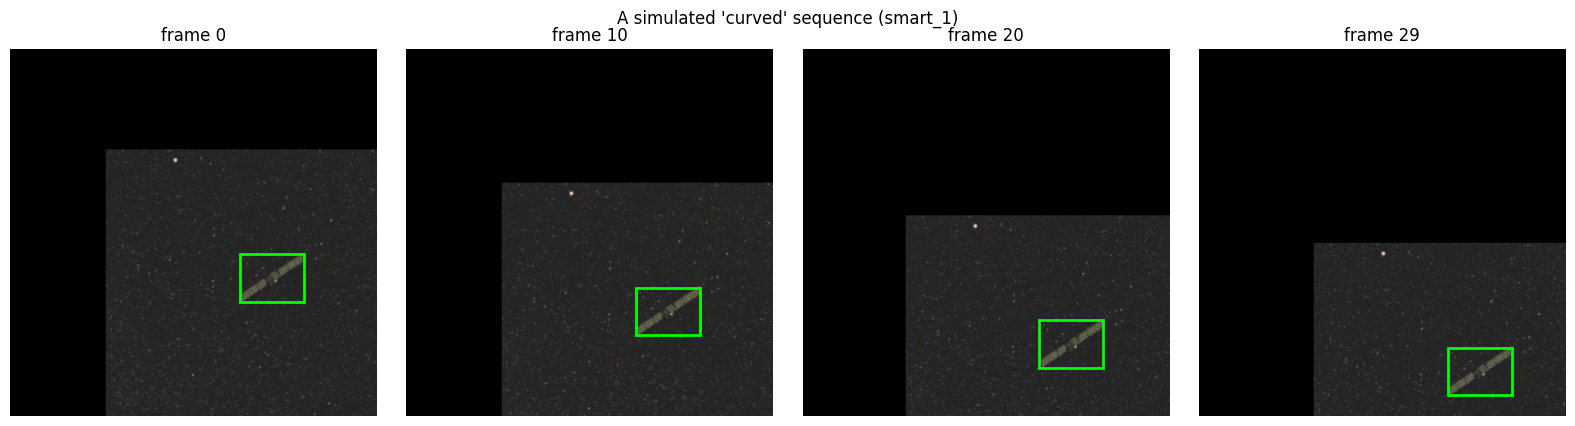

In [18]:
def box_center_wh(bbox):
    x1, y1, x2, y2 = bbox
    return np.array([(x1 + x2) / 2, (y1 + y2) / 2]), (x2 - x1), (y2 - y1)

def plan_path(kind, w, h, rng, max_tries=200):
    """Make a (SEQ_LEN, 2) path of centre positions that keeps the whole box inside the frame."""
    for _ in range(max_tries):
        speed   = rng.uniform(*SPEED_RANGE)
        heading = rng.uniform(0, 2 * np.pi)
        omega   = rng.uniform(*TURN_RATE_RANGE) * rng.choice([-1, 1]) if kind == "curved" else 0.0
        t_m     = int(rng.integers(SEQ_LEN // 3, 2 * SEQ_LEN // 3)) if kind == "maneuver" else None
        d_head  = rng.choice([-1, 1]) * rng.uniform(np.pi / 3, 2 * np.pi / 3) if kind == "maneuver" else 0.0
        pos = np.zeros((SEQ_LEN, 2))
        for t in range(1, SEQ_LEN):
            if t == t_m:
                heading += d_head                     # the sudden turn
            heading += omega
            pos[t] = pos[t - 1] + speed * np.array([np.cos(heading), np.sin(heading)])
        lo, hi, m = pos.min(axis=0), pos.max(axis=0), 3
        x_lo, x_hi = w / 2 + m - lo[0], IMG_W - w / 2 - m - hi[0]
        y_lo, y_hi = h / 2 + m - lo[1], IMG_H - h / 2 - m - hi[1]
        if x_lo <= x_hi and y_lo <= y_hi:
            start = np.array([rng.uniform(x_lo, x_hi), rng.uniform(y_lo, y_hi)])
            return pos + start, t_m
    return None            # object too big to move around inside the frame

def shift_image(img, dx, dy):
    """Slide an image by (dx, dy) pixels; the uncovered area becomes black."""
    out = np.zeros_like(img)
    h, w = img.shape[:2]
    sx0, sx1 = max(0, -dx), min(w, w - dx)
    sy0, sy1 = max(0, -dy), min(h, h - dy)
    out[sy0 + dy: sy1 + dy, sx0 + dx: sx1 + dx] = img[sy0:sy1, sx0:sx1]
    return out

def plan_sequence(rec, kind, rng):
    c0, w, h = box_center_wh(rec["bbox"])
    planned = plan_path(kind, w, h, rng)
    if planned is None:
        return None
    path, t_m = planned
    shifts = np.round(path - c0).astype(int)      # whole-pixel shifts
    return dict(shifts=shifts, true_xy=c0 + shifts, t_maneuver=t_m, w=w, h=h)

def render_sequence(img, shifts):
    return [shift_image(img, int(dx), int(dy)) for dx, dy in shifts]

# ---- visual check: 4 frames of one curved sequence ----
rng_demo = np.random.default_rng(0)
for rec in dev_recs:                       # first image whose object is small enough to move around
    plan = plan_sequence(rec, "curved", rng_demo)
    if plan is not None:
        break
img0 = np.array(Image.open(rec["path"]).convert("RGB"))
frames = render_sequence(img0, plan["shifts"])
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, t in zip(axes, [0, 10, 20, SEQ_LEN - 1]):
    ax.imshow(frames[t])
    cx, cy = plan["true_xy"][t]
    ax.add_patch(plt.Rectangle((cx - plan["w"] / 2, cy - plan["h"] / 2), plan["w"], plan["h"],
                               fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(f"frame {t}"); ax.axis("off")
plt.suptitle(f"A simulated 'curved' sequence ({rec['class']})")
plt.tight_layout(); plt.show()

In [19]:
def simulate_and_detect(rec, kind, rng, img):
    plan = plan_sequence(rec, kind, rng)
    if plan is None:
        return None
    frames = render_sequence(img, plan["shifts"])
    det = detect_frames(frames)
    return dict(kind=kind, is_anomaly=(kind == "maneuver"), true_xy=plan["true_xy"], det=det,
                t_maneuver=plan["t_maneuver"], wh=[float(plan["w"]), float(plan["h"])])

def build_dataset(recs, kinds, seed):
    rng = np.random.default_rng(seed)
    seqs, skipped = [], 0
    for rec in tqdm(recs):
        img = np.array(Image.open(rec["path"]).convert("RGB"))
        for kind in kinds:
            s = simulate_and_detect(rec, kind, rng, img)
            if s is None:
                skipped += 1
                continue
            s["id"] = f"{rec['filename']}_{kind}"
            seqs.append(s)
    print(f"built {len(seqs)} sequences ({skipped} skipped because the object was too big to move)")
    return seqs

use_dev  = dev_recs[:MAX_IMAGES]  if MAX_IMAGES else dev_recs
use_test = test_recs[:MAX_IMAGES] if MAX_IMAGES else test_recs
print("Building DEV sequences ...");  dev_seqs  = build_dataset(use_dev,  DEV_KINDS,  RNG_SEED)
print("Building TEST sequences ..."); test_seqs = build_dataset(use_test, TEST_KINDS, RNG_SEED + 1)
dev_seqs_all = dev_seqs
def detector_stats(seqs, name):
    det  = np.concatenate([s["det"] for s in seqs])
    true = np.concatenate([s["true_xy"] for s in seqs])
    miss = np.isnan(det[:, 0])
    err  = np.linalg.norm(det[~miss, :2] - true[~miss], axis=1)
    print(f"{name}: frames missed = {100 * miss.mean():.1f}% | centre error when found: "
          f"mean {err.mean():.1f}px, median {np.median(err):.1f}px, 95th percentile {np.percentile(err, 95):.1f}px")
detector_stats(dev_seqs, "DEV ")
detector_stats(test_seqs, "TEST")

# save a copy so you never have to repeat the slow step
with open(OUT_DIR / "sequences_detected.pkl", "wb") as f:
    pickle.dump((dev_seqs, test_seqs), f)
print("saved sequences_detected.pkl to", OUT_DIR)
# To skip this slow step next time, instead run:
#   dev_seqs, test_seqs = pickle.load(open(OUT_DIR / "sequences_detected.pkl", "rb"))

Building DEV sequences ...


  0%|          | 0/50 [00:00<?, ?it/s]

built 98 sequences (2 skipped because the object was too big to move)
Building TEST sequences ...


  0%|          | 0/50 [00:00<?, ?it/s]

built 144 sequences (6 skipped because the object was too big to move)
DEV : frames missed = 13.9% | centre error when found: mean 17.9px, median 7.3px, 95th percentile 43.2px
TEST: frames missed = 15.7% | centre error when found: mean 20.7px, median 5.0px, 95th percentile 90.6px
saved sequences_detected.pkl to C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module3_outputs


In [20]:
LOST_FRAC    = 0.2    # object found in fewer than 20% of frames -> "lost"
WRONG_PX     = 30     # median detector centre error above this many pixels -> "off" target
DROPOUT_PROB = 0.15   # simulated detector blinks. Set to 0 to switch off

def quality(s):
    """good / off / lost, judged on the detector's own output (before simulated dropout)."""
    det = s["det_full"] if "det_full" in s else s["det"]
    found = ~np.isnan(det[:, 0])
    if found.mean() < LOST_FRAC:
        return "lost"
    err = np.linalg.norm(det[found, :2] - s["true_xy"][found], axis=1)
    return "off" if np.median(err) > WRONG_PX else "good"

def add_dropout(seqs, p, seed):
    rng = np.random.default_rng(seed)
    for s in seqs:
        if "det_full" not in s:
            s["det_full"] = s["det"].copy()          # keep the untouched detector output
        det = s["det_full"].copy()
        det[rng.random(len(det)) < p] = np.nan
        s["det"] = det
    return seqs
                        # keep the full list so this cell can be re-run safely
add_dropout(dev_seqs_all, DROPOUT_PROB, RNG_SEED + 10)
add_dropout(test_seqs,    DROPOUT_PROB, RNG_SEED + 11)

from collections import Counter
print("dev  sequences:", dict(Counter(quality(s) for s in dev_seqs_all)))
print("test sequences:", dict(Counter(quality(s) for s in test_seqs)))

dev_seqs = [s for s in dev_seqs_all if quality(s) == "good"]     # tune / train only where the detector follows the object
print(f"\nusing {len(dev_seqs)} good dev sequences for tuning and LSTM training")
detector_stats(dev_seqs, "DEV  (good, after dropout)")
detector_stats(test_seqs, "TEST (all,  after dropout)")

dev  sequences: {'good': 78, 'lost': 10, 'off': 10}
test sequences: {'good': 112, 'off': 15, 'lost': 17}

using 78 good dev sequences for tuning and LSTM training
DEV  (good, after dropout): frames missed = 17.9% | centre error when found: mean 9.2px, median 6.1px, 95th percentile 23.2px
TEST (all,  after dropout): frames missed = 28.8% | centre error when found: mean 21.1px, median 5.0px, 95th percentile 92.6px


In [21]:
class KalmanCV:
    """Constant-velocity Kalman filter. State = [x, y, vx, vy] (pixels, pixels per frame)."""
    def __init__(self, sigma_a=0.2, r=3.0, gate=GATE_D2):
        self.r, self.gate, self.ready = r, gate, False
        self.F = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0], [0, 0, 0, 1]], float)
        self.H = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], float)
        G = np.array([[0.5], [1.0]])
        Q1 = (G @ G.T) * sigma_a ** 2                      # noise from random acceleration
        self.Q = np.zeros((4, 4))
        for i in range(2):
            self.Q[np.ix_([i, i + 2], [i, i + 2])] = Q1
        self.R = np.eye(2) * r ** 2
    def start(self, z, v):
        self.x = np.array([z[0], z[1], v[0], v[1]], float)
        self.P = np.diag([self.r ** 2, self.r ** 2, 3.0 ** 2, 3.0 ** 2])
        self.ready = True
    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
    def update(self, z):
        y = z - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R
        if y @ np.linalg.solve(S, y) > self.gate:          # too far from the prediction: ignore it
            return False
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ y
        I_KH = np.eye(4) - K @ self.H
        self.P = I_KH @ self.P @ I_KH.T + K @ self.R @ K.T
        return True
    def pos(self): return self.x[:2]
    def vel(self): return self.x[2:4]

def run_tracker(det_xy, tracker):
    """Feed one sequence of detections (T,2; NaN = missed) through a tracker -> positions (T,2), velocities (T,2)."""
    T = len(det_xy)
    est, vel = np.full((T, 2), np.nan), np.full((T, 2), np.nan)
    first_t, first_z, rejected = None, None, 0
    for t in range(T):
        z = det_xy[t]
        ok = not np.isnan(z[0])
        if not tracker.ready:                       # need two sensible detections to guess a starting velocity
            if ok and first_z is None:
                first_t, first_z = t, z
                est[t], vel[t] = z, (0.0, 0.0)
            elif ok:
                v = (z - first_z) / (t - first_t)
                if np.hypot(v[0], v[1]) > MAX_SPEED:        # impossible jump: one of the two was a false alarm
                    first_t, first_z = t, z                 # so start again from the newest detection
                    est[t], vel[t] = z, (0.0, 0.0)
                else:
                    tracker.start(z, v)
                    est[t], vel[t] = tracker.pos(), tracker.vel()
            elif first_z is not None:
                est[t], vel[t] = first_z, (0.0, 0.0)
            continue
        tracker.predict()
        if ok:
            if tracker.update(z):
                rejected = 0
            else:
                rejected += 1
                if rejected >= LOST_AFTER:                  # we have lost the object: restart the track
                    tracker.ready = False
                    first_t, first_z, rejected = t, z, 0
                    est[t], vel[t] = z, (0.0, 0.0)
                    continue
        est[t], vel[t] = tracker.pos(), tracker.vel()
    return est, vel

def fill_hold(xy):
    """Baseline: when the detector misses, just repeat its last answer."""
    xy = xy.copy()
    miss = np.isnan(xy[:, 0])
    last = None
    for t in range(len(xy)):
        if miss[t]:
            if last is not None:
                xy[t] = last
        else:
            last = xy[t].copy()
    valid = np.where(~np.isnan(xy[:, 0]))[0]
    if len(valid):
        xy[:valid[0]] = xy[valid[0]]
    return xy, miss

EVAL_START = 10     # ignore the first 10 frames (filters are still "warming up")


def score(seqs, make_tracker):
    errs = []
    for s in seqs:
        est, _ = run_tracker(s["det"][:, :2], make_tracker())

        e = np.linalg.norm(
            est[EVAL_START:] - s["true_xy"][EVAL_START:],
            axis=1
        )
        valid_errors = e[np.isfinite(e)]
        if len(valid_errors) > 0:
            errs.append(valid_errors)
    if len(errs) == 0:
        return float("inf")
    e = np.concatenate(errs)
    return float(np.sqrt(np.mean(e ** 2)))


# ---- tune sigma_a and r on the DEV sequences (never on test) ----
results = []
for sigma_a in [0.05, 0.1, 0.2, 0.4, 0.8]:
    for r in [1.0, 2.0, 4.0, 8.0]:
        results.append((score(dev_seqs, lambda: KalmanCV(sigma_a, r)), sigma_a, r))
results.sort()
print("best Kalman settings (RMSE in pixels, lower is better):")
for rm, sa, r in results[:3]:
    print(f"  sigma_a={sa}, r={r}  ->  RMSE {rm:.2f}")
kf_params = dict(sigma_a=results[0][1], r=results[0][2])
print("using:", kf_params)

best Kalman settings (RMSE in pixels, lower is better):
  sigma_a=0.8, r=4.0  ->  RMSE 11.67
  sigma_a=0.4, r=4.0  ->  RMSE 12.77
  sigma_a=0.8, r=8.0  ->  RMSE 12.91
using: {'sigma_a': 0.8, 'r': 4.0}


In [22]:
class UKF_CTRV:
    """Unscented Kalman filter with a constant-turn-rate-and-velocity model. State = [x, y, speed, heading, turn_rate]."""
    def __init__(self, q_v=0.2, q_th=0.05, q_w=0.01, r=3.0, q_pos=0.3, gate=GATE_D2,
                 alpha=0.3, beta=2.0, kappa=0.0):
        self.n, self.r, self.gate, self.ready = 5, r, gate, False
        n = self.n
        self.lam = alpha ** 2 * (n + kappa) - n
        self.Wm = np.full(2 * n + 1, 1.0 / (2 * (n + self.lam)))
        self.Wc = self.Wm.copy()
        self.Wm[0] = self.lam / (n + self.lam)
        self.Wc[0] = self.lam / (n + self.lam) + (1 - alpha ** 2 + beta)
        self.Q = np.diag([q_pos ** 2, q_pos ** 2, q_v ** 2, q_th ** 2, q_w ** 2])
        self.R = np.eye(2) * r ** 2

    @staticmethod
    def f(s):                                       # one step of the turning-motion model
        x, y, v, th, w = s
        if abs(w) > 1e-4:
            x = x + v / w * (np.sin(th + w) - np.sin(th))
            y = y + v / w * (np.cos(th) - np.cos(th + w))
        else:
            x = x + v * np.cos(th)
            y = y + v * np.sin(th)
        return np.array([x, y, v, th + w, w])

    def sigma_points(self, x, P):
        n = self.n
        P = (P + P.T) / 2
        for jitter in (0.0, 1e-9, 1e-6, 1e-4):
            try:
                L = np.linalg.cholesky((n + self.lam) * (P + jitter * np.eye(n)))
                break
            except np.linalg.LinAlgError:
                continue
        else:
            L = np.diag(np.sqrt(np.maximum(np.diag(P), 1e-9) * (n + self.lam)))
        pts = np.empty((2 * n + 1, n))
        pts[0] = x
        for i in range(n):
            pts[1 + i] = x + L[:, i]
            pts[1 + n + i] = x - L[:, i]
        return pts

    def start(self, z, v):
        speed = float(np.hypot(v[0], v[1]))
        self.x = np.array([z[0], z[1], speed, np.arctan2(v[1], v[0]), 0.0])
        self.P = np.diag([self.r ** 2, self.r ** 2, 3.0 ** 2, 0.5 ** 2, 0.1 ** 2])
        self.ready = True

    def predict(self):
        pts = self.sigma_points(self.x, self.P)
        pf = np.array([self.f(p) for p in pts])
        self.x = self.Wm @ pf
        d = pf - self.x
        self.P = (d.T * self.Wc) @ d + self.Q

    def update(self, z):
        pts = self.sigma_points(self.x, self.P)
        zs = pts[:, :2]                              # we only measure position
        zp = self.Wm @ zs
        dz = zs - zp
        S = (dz.T * self.Wc) @ dz + self.R
        y = z - zp
        if y @ np.linalg.solve(S, y) > self.gate:
            return False
        Pxz = ((pts - self.x).T * self.Wc) @ dz
        K = Pxz @ np.linalg.inv(S)
        self.x = self.x + K @ y
        self.P = self.P - K @ S @ K.T
        self.P = (self.P + self.P.T) / 2
        return True

    def pos(self): return self.x[:2]
    def vel(self): return self.x[2] * np.array([np.cos(self.x[3]), np.sin(self.x[3])])

# ---- tune on the DEV sequences (uses the same r that worked for the Kalman filter) ----
tune_seqs = dev_seqs[:100]
results = []
for q_v in [0.05, 0.2, 0.5]:
    for q_th in [0.02, 0.05, 0.1]:
        for q_w in [0.002, 0.005, 0.01, 0.02]:
            sc = score(tune_seqs, lambda: UKF_CTRV(q_v, q_th, q_w, r=kf_params["r"]))
            results.append((sc, q_v, q_th, q_w))
results.sort()
print("best UKF settings (RMSE in pixels, lower is better):")
for rm, a, b, c in results[:3]:
    print(f"  q_v={a}, q_th={b}, q_w={c}  ->  RMSE {rm:.2f}")
ukf_params = dict(q_v=results[0][1], q_th=results[0][2], q_w=results[0][3], r=kf_params["r"])
print("using:", ukf_params)

best UKF settings (RMSE in pixels, lower is better):
  q_v=0.5, q_th=0.1, q_w=0.005  ->  RMSE 12.33
  q_v=0.5, q_th=0.1, q_w=0.01  ->  RMSE 12.33
  q_v=0.5, q_th=0.1, q_w=0.02  ->  RMSE 12.34
using: {'q_v': 0.5, 'q_th': 0.1, 'q_w': 0.005, 'r': 4.0}


In [23]:
WIN, SCALE = 10, 50.0

def make_windows(seqs):
    X, Y = [], []
    for s in seqs:
        filled, miss = fill_hold(s["det"][:, :2])
        if np.isnan(filled).any():
            continue
        for t in range(WIN - 1, len(filled)):
            win, flag = filled[t - WIN + 1: t + 1], miss[t - WIN + 1: t + 1]
            ref = win[-1]
            X.append(np.concatenate([(win - ref) / SCALE, flag[:, None].astype(float)], axis=1))
            Y.append((s["true_xy"][t] - ref) / SCALE)
    return np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32)

class TrackLSTM(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(3, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 2)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1])

split = int(0.85 * len(dev_seqs))
Xtr, Ytr = make_windows(dev_seqs[:split])
Xva, Yva = make_windows(dev_seqs[split:])
print("training windows:", len(Xtr), "| validation windows:", len(Xva))
Xtr, Ytr, Xva, Yva = [torch.tensor(a).to(device) for a in (Xtr, Ytr, Xva, Yva)]

torch.manual_seed(0)
lstm = TrackLSTM().to(device)
opt = torch.optim.Adam(lstm.parameters(), lr=3e-3)
loss_fn = nn.MSELoss()
best_va, best_state = 1e9, None
for epoch in range(1, 81):
    lstm.train()
    perm = torch.randperm(len(Xtr), device=device)
    for i in range(0, len(Xtr), 128):
        idx = perm[i:i + 128]
        opt.zero_grad()
        loss = loss_fn(lstm(Xtr[idx]), Ytr[idx])
        loss.backward()
        opt.step()
    lstm.eval()
    with torch.no_grad():
        va = loss_fn(lstm(Xva), Yva).item() if len(Xva) else float("nan")
    if len(Xva) and va < best_va:
        best_va, best_state = va, {k: v.clone() for k, v in lstm.state_dict().items()}
    if epoch % 10 == 0:
        print(f"epoch {epoch:2d} | validation error: {math.sqrt(va) * SCALE:.2f} px")
if best_state is not None:
    lstm.load_state_dict(best_state)
lstm.eval()

def lstm_estimate(s):
    filled, miss = fill_hold(s["det"][:, :2])
    est = np.full((len(filled), 2), np.nan)
    if np.isnan(filled).any():
        return est
    feats, refs, ts = [], [], []
    for t in range(WIN - 1, len(filled)):
        win, flag = filled[t - WIN + 1: t + 1], miss[t - WIN + 1: t + 1]
        refs.append(win[-1]); ts.append(t)
        feats.append(np.concatenate([(win - win[-1]) / SCALE, flag[:, None].astype(float)], axis=1))
    with torch.no_grad():
        off = lstm(torch.tensor(np.array(feats, dtype=np.float32)).to(device)).cpu().numpy() * SCALE
    est[ts] = np.array(refs) + off
    return est
torch.save(lstm.state_dict(), OUT_DIR / "lstm_tracker.pt")
print("LSTM trained and saved.")

training windows: 1386 | validation windows: 252
epoch 10 | validation error: 20.07 px
epoch 20 | validation error: 20.74 px
epoch 30 | validation error: 20.92 px
epoch 40 | validation error: 21.65 px
epoch 50 | validation error: 22.04 px
epoch 60 | validation error: 22.59 px
epoch 70 | validation error: 22.29 px
epoch 80 | validation error: 22.92 px
LSTM trained and saved.


In [24]:
# ---- which test sequences can the trackers be fairly judged on? ----
normal_test = [s for s in test_seqs if s["kind"] != "maneuver"]
groups = {"good": [], "off": [], "lost": []}
for i, s in enumerate(normal_test):
    groups[quality(s)].append(i)
print(f"Normal test sequences: {len(normal_test)}")
print(f"  good  (detector follows the object)          : {len(groups['good'])}")
print(f"  off   (detector centre > {WRONG_PX}px from the object): {len(groups['off'])}   <- Module 1 problem")
print(f"  lost  (object found in < {int(LOST_FRAC * 100)}% of frames)      : {len(groups['lost'])}   <- Module 1 problem")

methods = {
    "Raw detector (hold last)": lambda s: (fill_hold(s["det"][:, :2])[0], None),
    "Kalman filter":            lambda s: run_tracker(s["det"][:, :2], KalmanCV(**kf_params)),
    "UKF (turning model)":      lambda s: run_tracker(s["det"][:, :2], UKF_CTRV(**ukf_params)),
    "LSTM":                     lambda s: (lstm_estimate(s), None),
}
ests = {name: [fn(s) for s in normal_test] for name, fn in methods.items()}

def true_vel(s):
    v = np.zeros_like(s["true_xy"]); v[1:] = np.diff(s["true_xy"], axis=0); return v

def score_table(idx, title):
    out = {}
    print(f"\n{title}  ({len(idx)} sequences)")
    print(f"{'method':26s} {'overall px':>11s} {'dropped px':>11s} {'detected px':>12s} {'median px':>10s} {'speed err':>10s}")
    cat = lambda L: np.concatenate(L) if L else np.array([])
    rmse = lambda a: float(np.sqrt(np.mean(a ** 2))) if len(a) else float("nan")
    for name in methods:
        e_all, e_drop, e_det, v_err = [], [], [], []
        for i in idx:
            s = normal_test[i]
            ok = np.zeros(len(s["true_xy"]), bool); ok[EVAL_START:] = True
            for other in methods:                              # the same frames for every method
                ok &= np.isfinite(ests[other][i][0]).all(axis=1)
            missed = np.isnan(s["det"][:, 0])
            err = np.linalg.norm(ests[name][i][0] - s["true_xy"], axis=1)
            e_all.append(err[ok]); e_drop.append(err[ok & missed]); e_det.append(err[ok & ~missed])
            vel = ests[name][i][1]
            if vel is not None:
                tv = true_vel(s)
                v_err.append(np.abs(np.hypot(vel[:, 0], vel[:, 1]) - np.hypot(tv[:, 0], tv[:, 1]))[ok])
        a_all, a_drop, a_det, a_v = cat(e_all), cat(e_drop), cat(e_det), cat(v_err)
        out[name] = dict(overall=rmse(a_all), dropped=rmse(a_drop), detected=rmse(a_det),
                         median=float(np.median(a_all)) if len(a_all) else float("nan"),
                         speed_err=float(np.mean(a_v)) if len(a_v) else float("nan"),
                         frames=int(len(a_all)), dropped_frames=int(len(a_drop)))
        r = out[name]
        print(f"{name:26s} {r['overall']:11.2f} {r['dropped']:11.2f} {r['detected']:12.2f} {r['median']:10.2f} {r['speed_err']:10.2f}")
    return out

summary     = score_table(groups["good"], "TRACKING SCORE: sequences where the detector follows the object")
summary_all = score_table(list(range(len(normal_test))), "FOR REFERENCE: all sequences, including detector failures")

Normal test sequences: 96
  good  (detector follows the object)          : 75
  off   (detector centre > 30px from the object): 10   <- Module 1 problem
  lost  (object found in < 20% of frames)      : 11   <- Module 1 problem

TRACKING SCORE: sequences where the detector follows the object  (75 sequences)
method                      overall px  dropped px  detected px  median px  speed err
Raw detector (hold last)         26.04       12.81        28.07       5.14        nan
Kalman filter                    23.05       11.33        24.85       4.67       0.50
UKF (turning model)              23.08       11.24        24.88       4.59       0.53
LSTM                             26.12       13.05        28.13       5.22        nan

FOR REFERENCE: all sequences, including detector failures  (96 sequences)
method                      overall px  dropped px  detected px  median px  speed err
Raw detector (hold last)         56.75       69.20        52.62       6.55        nan
Kalman filter  

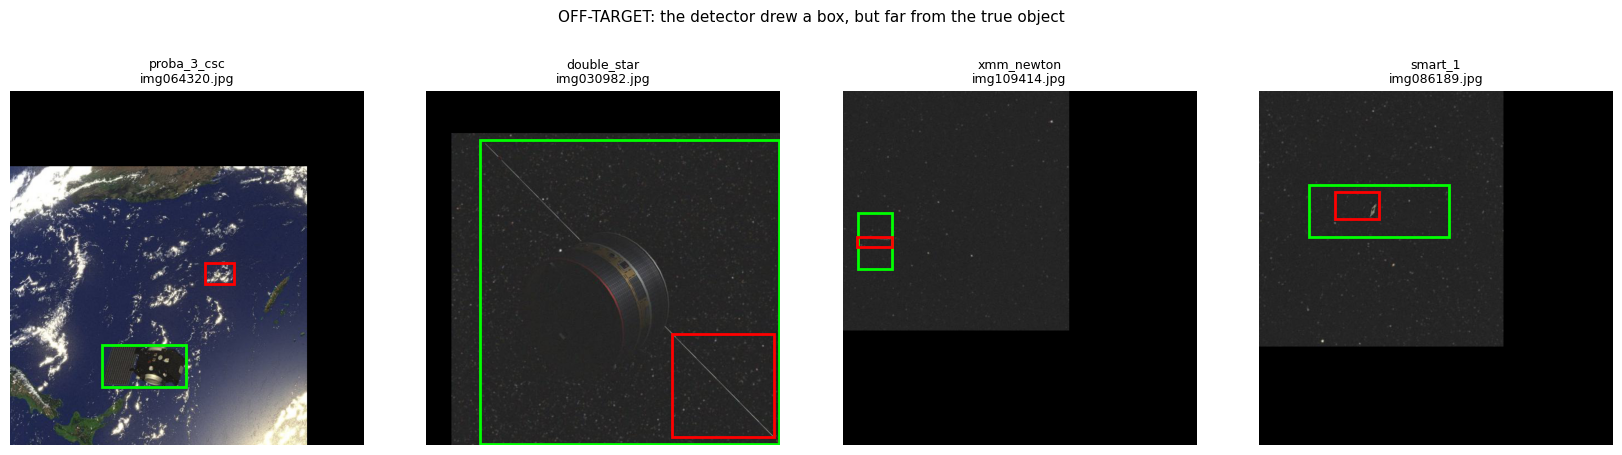

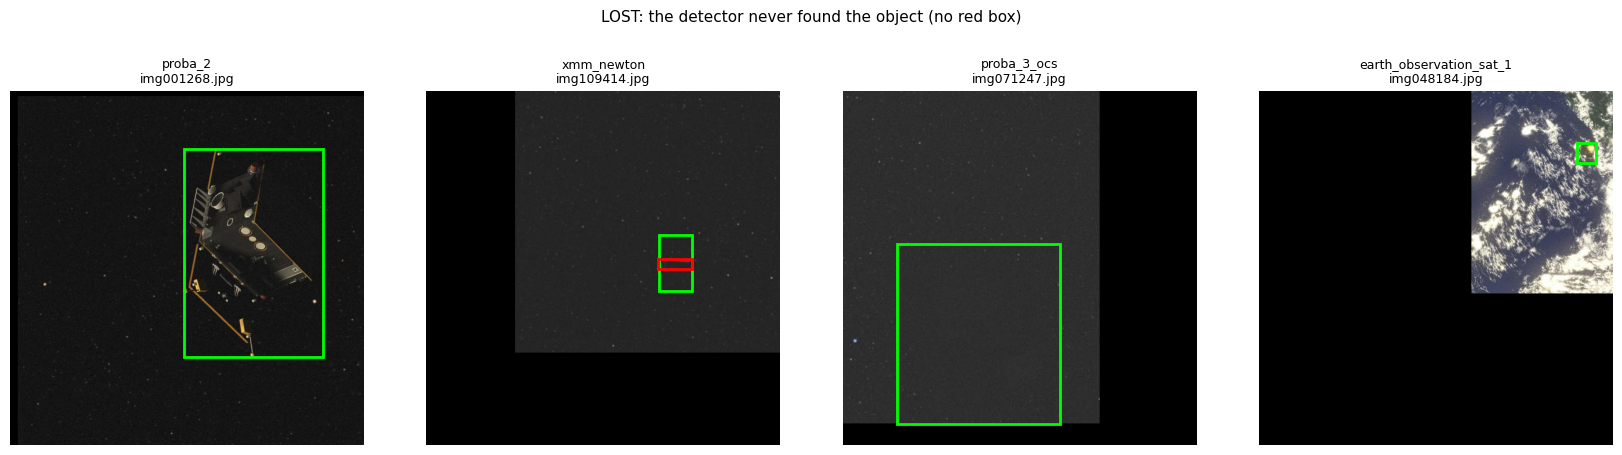

In [25]:
# ---- look at the sequences the detector failed on (green = true box, red = detector's box) ----
rec_by_name = {r["filename"]: r for r in dev_recs + test_recs}

def show_problem_sequences(idx_list, title, max_n=4):
    seen, picks = set(), []
    for i in idx_list:                                   # one picture per image, not one per sequence
        fn = normal_test[i]["id"].rsplit("_", 1)[0]
        if fn not in seen:
            seen.add(fn); picks.append(i)
    picks = picks[:max_n]
    if not picks:
        print(f"{title}: none"); return
    fig, axes = plt.subplots(1, len(picks), figsize=(4.2 * len(picks), 4.6), squeeze=False)
    for ax, i in zip(axes[0], picks):
        s = normal_test[i]
        det = s["det_full"] if "det_full" in s else s["det"]
        fn = s["id"].rsplit("_", 1)[0]
        rec = rec_by_name[fn]
        c0, _, _ = box_center_wh(rec["bbox"])
        found = np.where(~np.isnan(det[:, 0]))[0]
        t = int(found[0]) if len(found) else 0
        dx, dy = np.round(s["true_xy"][t] - c0).astype(int)
        ax.imshow(shift_image(np.array(Image.open(rec["path"]).convert("RGB")), int(dx), int(dy)))
        w, h = s["wh"]; cx, cy = s["true_xy"][t]
        ax.add_patch(plt.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, edgecolor="lime", linewidth=2))
        if len(found):
            dcx, dcy, dw, dh = det[t, :4]
            ax.add_patch(plt.Rectangle((dcx - dw / 2, dcy - dh / 2), dw, dh, fill=False, edgecolor="red", linewidth=2))
        ax.set_title(f"{rec['class']}\n{fn}", fontsize=9); ax.axis("off")
    plt.suptitle(title, fontsize=11); plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()

show_problem_sequences(groups["off"],  "OFF-TARGET: the detector drew a box, but far from the true object")
show_problem_sequences(groups["lost"], "LOST: the detector never found the object (no red box)")

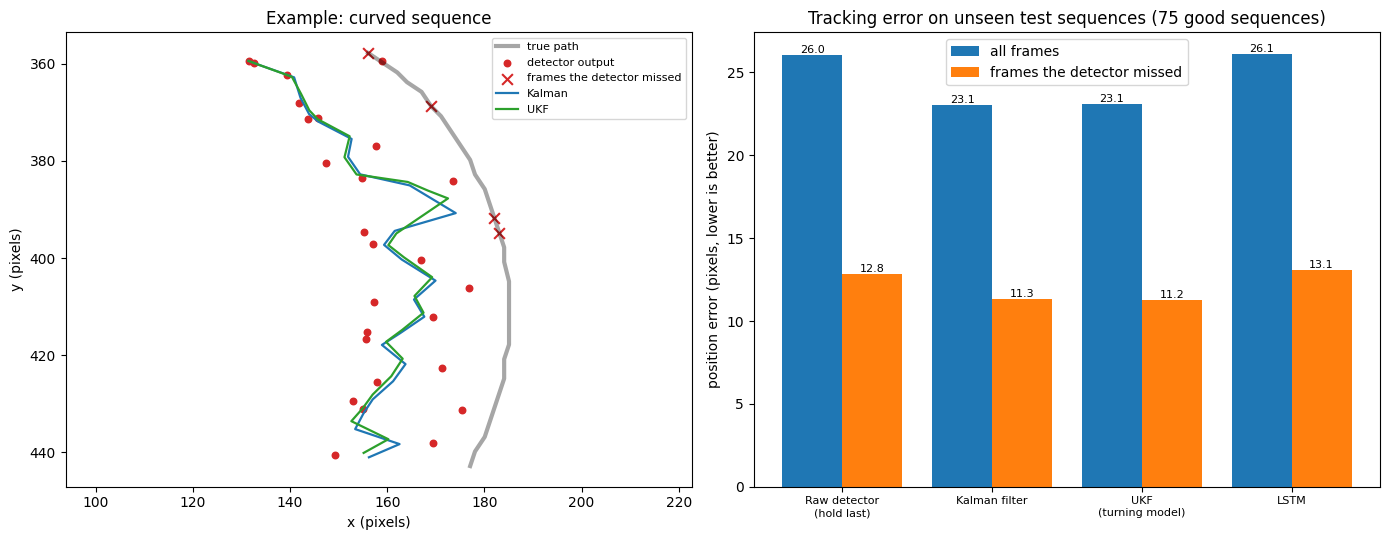

picture saved to C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module3_outputs\module3_results.png - use it on your slides


In [26]:
# ---- picture 1: one example trajectory ----
good_idx = groups["good"]
n_dropped = lambda i: int(np.isnan(normal_test[i]["det"][:, 0]).sum())
cands = ([i for i in good_idx if normal_test[i]["kind"] == "curved" and n_dropped(i) > 0]
         or [i for i in good_idx if n_dropped(i) > 0] or good_idx)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
if cands:
    i = cands[0]; s = normal_test[i]
    ax.plot(*s["true_xy"].T, "k-", lw=3, alpha=0.35, label="true path")
    ok = ~np.isnan(s["det"][:, 0])
    ax.scatter(*s["det"][ok, :2].T, c="tab:red", s=22, label="detector output")
    ax.scatter(*s["true_xy"][~ok].T, marker="x", c="tab:red", s=60, label="frames the detector missed")
    ax.plot(*ests["Kalman filter"][i][0].T, "tab:blue", lw=1.6, label="Kalman")
    ax.plot(*ests["UKF (turning model)"][i][0].T, "tab:green", lw=1.6, label="UKF")
    ax.invert_yaxis(); ax.set_aspect("equal", adjustable="datalim"); ax.legend(fontsize=8)
    ax.set_title(f"Example: {s['kind']} sequence")
    ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")
else:
    ax.axis("off"); ax.text(0.5, 0.5, "no sequence where the detector follows the object", ha="center")

# ---- picture 2: error by method ----
ax = axes[1]
names = list(methods); xs = np.arange(len(names))
all_vals  = np.array([summary[n]["overall"] for n in names])
drop_vals = np.array([summary[n]["dropped"] for n in names])
ax.bar(xs - 0.2, np.nan_to_num(all_vals), 0.4, label="all frames")
if np.isfinite(drop_vals).any():
    ax.bar(xs + 0.2, np.nan_to_num(drop_vals), 0.4, label="frames the detector missed")
for x, v in zip(xs - 0.2, all_vals):
    if np.isfinite(v): ax.text(x, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
for x, v in zip(xs + 0.2, drop_vals):
    if np.isfinite(v): ax.text(x, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=8)
ax.set_ylabel("position error (pixels, lower is better)")
ax.set_title(f"Tracking error on unseen test sequences ({len(good_idx)} good sequences)")
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "module3_results.png", dpi=130)
plt.show()
print("picture saved to", OUT_DIR / "module3_results.png", "- use it on your slides")

In [27]:
# ---- Step 12: save the trajectories for Module 4 ----
def clean(a):
    return [[None if np.isnan(v) else round(float(v), 3) for v in row] for row in a]

def pack(seqs):
    out = []
    for s in seqs:
        kf_p,  kf_v  = run_tracker(s["det"][:, :2], KalmanCV(**kf_params))
        ukf_p, ukf_v = run_tracker(s["det"][:, :2], UKF_CTRV(**ukf_params))
        out.append(dict(id=s["id"], kind=s["kind"], is_anomaly=bool(s["is_anomaly"]), quality=quality(s),
                        t_maneuver=s["t_maneuver"], true_xy=clean(s["true_xy"]), det=clean(s["det"][:, :2]),
                        kf_xy=clean(kf_p), kf_vel=clean(kf_v), ukf_xy=clean(ukf_p), ukf_vel=clean(ukf_v)))
    return out

with open(OUT_DIR / "trajectories_for_module4.json", "w") as f:
    json.dump(dict(dev=pack(dev_seqs), test=pack(test_seqs)), f)
with open(OUT_DIR / "module3_config.json", "w") as f:
    json.dump(dict(kalman=kf_params, ukf=ukf_params, seq_len=SEQ_LEN, gate_d2=GATE_D2, results=summary), f, indent=2)
print(f"saved {len(dev_seqs)} dev + {len(test_seqs)} test sequences to {OUT_DIR}")
print("test sequences by kind:", dict(Counter(s["kind"] for s in test_seqs)))

saved 78 dev + 144 test sequences to C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module3_outputs
test sequences by kind: {'linear': 48, 'curved': 48, 'maneuver': 48}


In [28]:
import os
from pathlib import Path

# If you run this module on its own (fresh kernel), define the folders here; otherwise the earlier cells already did.
try:
    WORK_DIR
except NameError:
    BASE_DIR = Path(r"C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A")
    WORK_DIR = BASE_DIR / "nova_work"

M3_DIR  = WORK_DIR / "module3_outputs"
HANDOFF = M3_DIR / "trajectories_for_module4.json"
M4_DIR  = WORK_DIR / "module4_outputs"          # everything Module 4 creates is saved here
M4_DIR.mkdir(parents=True, exist_ok=True)

print(("FOUND    " if HANDOFF.exists() else "MISSING  ") + str(HANDOFF))
assert HANDOFF.exists(), ("Run Module 3 in full mode and then its 'save for Module 4' cell. "
                          "It creates this file.")

FOUND    C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module3_outputs\trajectories_for_module4.json


In [29]:
import json, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from collections import Counter

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

TRACKER     = "kf"     # "kf" or "ukf"
START       = 5        # ignore the first frames while the tracker warms up
SMOOTH      = 5        # frames used to average the turn rate (see Step 4)
HIDDEN, LATENT = 32, 4 # network size. LATENT is the bottleneck (see Step 5)
EPOCHS, LR, BATCH = 300, 3e-3, 32
THRESH_PCT  = 95
SCORE_MODE  = "mean"   # "mean" or "max"

Running on: cpu


In [30]:
with open(HANDOFF, encoding="utf-8") as f:
    H = json.load(f)

def to_arr(rows):
    return np.array([[np.nan if v is None else v for v in r] for r in rows], float)

def prep(seqs):
    return [dict(id=s["id"], kind=s["kind"], is_anomaly=bool(s["is_anomaly"]), t_maneuver=s["t_maneuver"],
                 quality=s.get("quality", "good"), vel=to_arr(s[f"{TRACKER}_vel"]),
                 xy=to_arr(s[f"{TRACKER}_xy"])) for s in seqs]

dev, test = prep(H["dev"]), prep(H["test"])
print("dev  trajectories:", len(dev),  dict(Counter(s["kind"] for s in dev)))
print("test trajectories:", len(test), dict(Counter(s["kind"] for s in test)))
print("test quality     :", dict(Counter(s["quality"] for s in test)))

dev  trajectories: 78 {'linear': 39, 'curved': 39}
test trajectories: 144 {'linear': 48, 'curved': 48, 'maneuver': 48}
test quality     : {'good': 112, 'off': 15, 'lost': 17}


usable dev (normal) : 77   | usable test normal: 82   | usable test anomalies: 41
feature array shape  : (77, 24, 4) = (trajectories, time steps, 4 signals)


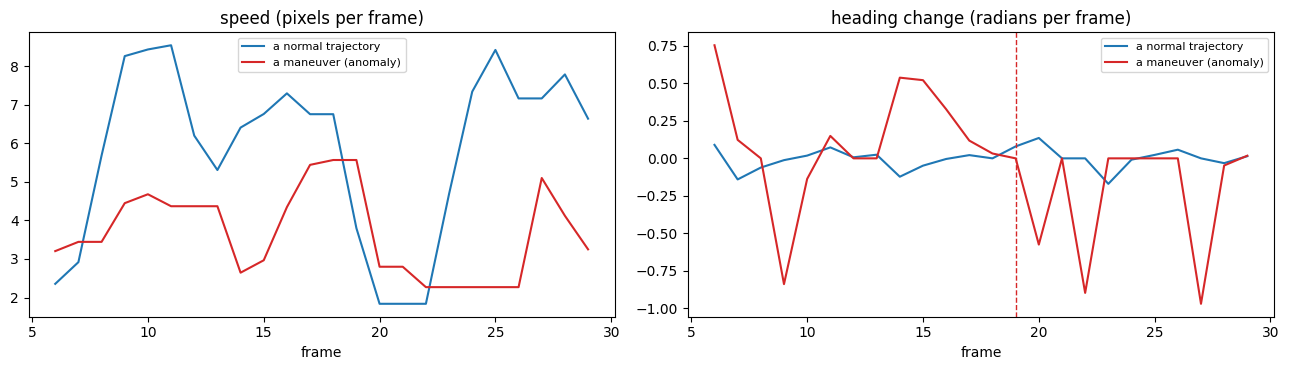

In [31]:
FEATURE_NAMES = ["speed", "heading change", "speed change", "smoothed turn rate"]

def to_features(vel):
    """(T,2) velocity in px/frame -> (T-START-1, 4) array of the four signals, or None if unusable."""
    v = np.asarray(vel, float)[START:]
    if len(v) < SMOOTH + 2 or not np.isfinite(v).all():
        return None
    speed = np.hypot(v[:, 0], v[:, 1])
    theta = np.unwrap(np.arctan2(v[:, 1], v[:, 0]))
    dth   = np.diff(theta)                                   # heading change per frame
    dsp   = np.diff(speed)                                   # speed change per frame
    pad   = np.concatenate([np.full(SMOOTH - 1, dth[0]), dth])
    smooth = np.convolve(pad, np.ones(SMOOTH) / SMOOTH, mode="valid")
    return np.stack([speed[1:], dth, dsp, smooth], axis=1).astype(np.float32)

def make_set(seqs, keep):
    X, meta = [], []
    for s in seqs:
        if not keep(s):
            continue
        f = to_features(s["vel"])
        if f is not None:
            X.append(f); meta.append(s)
    return (np.stack(X) if X else np.zeros((0, 1, 4), np.float32)), meta

X_dev,  dev_meta  = make_set(dev,  lambda s: not s["is_anomaly"])
X_te_n, te_n_meta = make_set(test, lambda s: not s["is_anomaly"] and s["quality"] != "lost")
X_te_a, te_a_meta = make_set(test, lambda s:     s["is_anomaly"] and s["quality"] != "lost")
print(f"usable dev (normal) : {len(X_dev)}   | usable test normal: {len(X_te_n)}   | usable test anomalies: {len(X_te_a)}")
print("feature array shape  :", X_dev.shape, "= (trajectories, time steps, 4 signals)")
assert len(X_dev) >= 10 and len(X_te_a) >= 1 and len(X_te_n) >= 1, \
    "Too little data. Re-run Module 3 with MAX_IMAGES = None, then its save cell."
if len(X_dev) < 60:
    print("WARNING: fewer than 60 training trajectories. The numbers will be noisy; use the full Module 3 run for the report.")

# ---- picture: what the two signals look like ----
t_axis = np.arange(START + 1, START + 1 + X_dev.shape[1])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for k, (X, meta, name, col) in enumerate([(X_te_n, te_n_meta, "a normal trajectory", "tab:blue"),
                                         (X_te_a, te_a_meta, "a maneuver (anomaly)", "tab:red")]):
    axes[0].plot(t_axis, X[0][:, 0], col, label=name)
    axes[1].plot(t_axis, X[0][:, 1], col, label=name)
    if meta[0]["t_maneuver"] is not None:
        axes[1].axvline(meta[0]["t_maneuver"], color=col, ls="--", lw=1)
axes[0].set_title("speed (pixels per frame)"); axes[1].set_title("heading change (radians per frame)")
for ax in axes: ax.set_xlabel("frame"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

training trajectories: 62 | validation trajectories: 15
epoch  50 | train loss 7.8211 | validation loss 20.9899
epoch 100 | train loss 7.0145 | validation loss 21.0135
epoch 150 | train loss 6.5118 | validation loss 21.2408
stopped early at epoch 153 (validation loss stopped improving)
best validation loss 20.8319  |  training took 6s


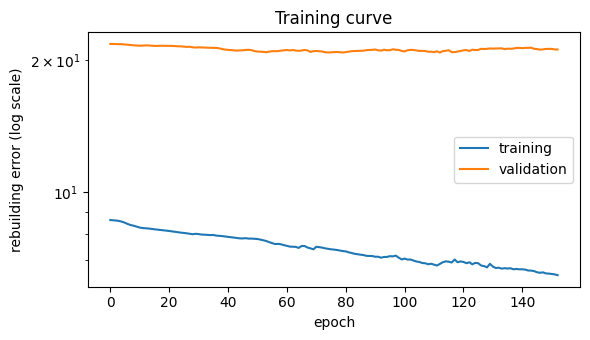

In [32]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, n_feat=4, hidden=HIDDEN, latent=LATENT):
        super().__init__()
        self.enc    = nn.LSTM(n_feat, hidden, batch_first=True)
        self.to_z   = nn.Linear(hidden, latent)       # the bottleneck
        self.from_z = nn.Linear(latent, hidden)
        self.dec    = nn.LSTM(hidden, hidden, batch_first=True)
        self.out    = nn.Linear(hidden, n_feat)
    def forward(self, x):                              # x: (batch, time, features)
        _, (h, _) = self.enc(x)
        z = self.to_z(h[-1])                           # (batch, latent)
        d = self.from_z(z).unsqueeze(1).repeat(1, x.shape[1], 1)
        y, _ = self.dec(d)
        return self.out(y)

# split the normal dev trajectories 80/20 into train / validation
perm = np.random.default_rng(SEED).permutation(len(X_dev))
n_val = max(2, int(0.2 * len(X_dev)))
X_val, X_train = X_dev[perm[:n_val]], X_dev[perm[n_val:]]       # still unscaled ("raw") signals
print("training trajectories:", len(X_train), "| validation trajectories:", len(X_val))

# rescale each signal using the NORMAL TRAINING data only (median and robust spread)
flat = X_train.reshape(-1, X_train.shape[2])
FEAT_MU = np.median(flat, axis=0)
FEAT_SD = 1.4826 * np.median(np.abs(flat - FEAT_MU), axis=0) + 1e-6
def standardize(X):
    return ((np.asarray(X, np.float32) - FEAT_MU) / FEAT_SD).astype(np.float32)

ae_model = LSTMAutoencoder().to(device)
opt = torch.optim.Adam(ae_model.parameters(), lr=LR)
loss_fn = nn.MSELoss()
xt_train = torch.tensor(standardize(X_train), device=device)
xt_val   = torch.tensor(standardize(X_val), device=device)

best_val, best_state, wait, hist = 1e9, None, 0, []
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    ae_model.train()
    idx = torch.randperm(len(xt_train), device=device)
    for i in range(0, len(idx), BATCH):
        xb = xt_train[idx[i:i + BATCH]]
        opt.zero_grad()
        loss_fn(ae_model(xb), xb).backward()
        opt.step()
    ae_model.eval()
    with torch.no_grad():
        tr = loss_fn(ae_model(xt_train), xt_train).item()
        va = loss_fn(ae_model(xt_val), xt_val).item()
    hist.append((tr, va))
    if va < best_val - 1e-6:
        best_val, wait = va, 0
        best_state = {k: v.clone() for k, v in ae_model.state_dict().items()}
    else:
        wait += 1
    if epoch % 50 == 0:
        print(f"epoch {epoch:3d} | train loss {tr:.4f} | validation loss {va:.4f}")
    if wait >= 40:
        print(f"stopped early at epoch {epoch} (validation loss stopped improving)")
        break
ae_model.load_state_dict(best_state); ae_model.eval()
print(f"best validation loss {best_val:.4f}  |  training took {time.time() - t0:.0f}s")

plt.figure(figsize=(6, 3.5))
plt.plot([h[0] for h in hist], label="training"); plt.plot([h[1] for h in hist], label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("rebuilding error (log scale)"); plt.legend(); plt.title("Training curve")
plt.tight_layout(); plt.show()

threshold (score)     : 103.3965   [95th percentile of validation-normal scores]
normal  test scores   : median 1.4661, 95th pct 108.6653
anomaly test scores   : median 7.5607, 5th pct 2.3154


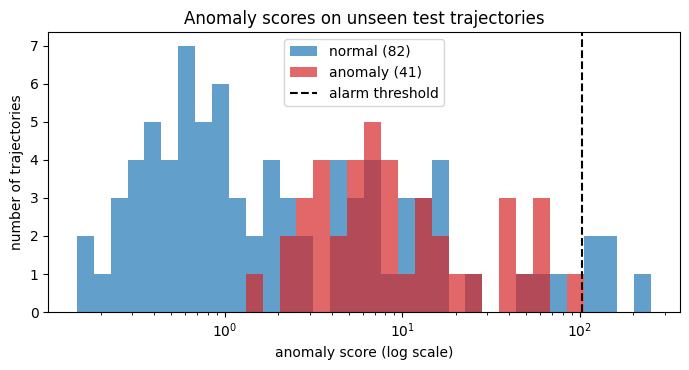

In [33]:
@torch.no_grad()
def step_errors(X):
    """(N, T, 4) raw signals -> (N, T) squared rebuilding error at every time step."""
    ae_model.eval()
    x = torch.tensor(standardize(X), device=device)
    return ((ae_model(x) - x) ** 2).mean(dim=2).cpu().numpy()

def seq_score(E, mode=None):
    mode = mode or SCORE_MODE
    return E.mean(axis=1) if mode == "mean" else E.max(axis=1)

E_val, E_te_n, E_te_a = step_errors(X_val), step_errors(X_te_n), step_errors(X_te_a)
THRESHOLD = float(np.percentile(seq_score(E_val), THRESH_PCT))     # alarm threshold on the trajectory score
STEP_THR  = float(np.percentile(E_val, 99))                         # per-frame threshold (used to say WHEN)
sn, sa = seq_score(E_te_n), seq_score(E_te_a)

print(f"threshold (score)     : {THRESHOLD:.4f}   [{THRESH_PCT}th percentile of validation-normal scores]")
print(f"normal  test scores   : median {np.median(sn):.4f}, 95th pct {np.percentile(sn, 95):.4f}")
print(f"anomaly test scores   : median {np.median(sa):.4f}, 5th pct {np.percentile(sa, 5):.4f}")

hi = max(sn.max(), sa.max())
bins = np.logspace(np.log10(max(min(sn.min(), sa.min()), 1e-6)), np.log10(hi * 1.05), 35)
plt.figure(figsize=(7, 3.8))
plt.hist(sn, bins=bins, alpha=0.7, label=f"normal ({len(sn)})", color="tab:blue")
plt.hist(sa, bins=bins, alpha=0.7, label=f"anomaly ({len(sa)})", color="tab:red")
plt.axvline(THRESHOLD, color="k", ls="--", label="alarm threshold")
plt.xscale("log"); plt.xlabel("anomaly score (log scale)"); plt.ylabel("number of trajectories"); plt.legend()
plt.title("Anomaly scores on unseen test trajectories")
plt.tight_layout(); plt.show()

In [34]:
def roc_auc(s_norm, s_anom):
    a, n = np.asarray(s_anom)[:, None], np.asarray(s_norm)[None, :]
    return float((a > n).mean() + 0.5 * (a == n).mean())

def metrics(s_norm, s_anom, thr):
    tp, fn = int((s_anom > thr).sum()), int((s_anom <= thr).sum())
    fp, tn = int((s_norm > thr).sum()), int((s_norm <= thr).sum())
    prec = tp / (tp + fp) if tp + fp else float("nan")
    rec  = tp / (tp + fn) if tp + fn else float("nan")
    f1   = 2 * prec * rec / (prec + rec) if tp > 0 else 0.0
    return dict(tp=tp, fn=fn, fp=fp, tn=tn, precision=prec, recall=rec, f1=f1, false_alarm_rate=fp / (fp + tn))

# ---- the simple rule (no learning): z-score of heading change and speed change ----
MU_T, SD_T = X_train[:, :, 1].mean(), X_train[:, :, 1].std() + 1e-6     # heading change
MU_S, SD_S = X_train[:, :, 2].mean(), X_train[:, :, 2].std() + 1e-6     # speed change
def rule_score(X):
    X = np.asarray(X, np.float32)
    z = np.sqrt(((X[:, :, 1] - MU_T) / SD_T) ** 2 + ((X[:, :, 2] - MU_S) / SD_S) ** 2)
    return z.max(axis=1)
RULE_THR = float(np.percentile(rule_score(X_val), THRESH_PCT))
rn, ra = rule_score(X_te_n), rule_score(X_te_a)

m_ae, m_rule = metrics(sn, sa, THRESHOLD), metrics(rn, ra, RULE_THR)
auc_ae, auc_rule = roc_auc(sn, sa), roc_auc(rn, ra)
auc_ae_other = roc_auc(seq_score(E_te_n, "max" if SCORE_MODE == "mean" else "mean"),
                       seq_score(E_te_a, "max" if SCORE_MODE == "mean" else "mean"))

print(f"{'method':32s} {'AUC':>6s} {'recall':>7s} {'precision':>10s} {'false alarms':>13s} {'F1':>6s}")
for name, auc, m in [("LSTM autoencoder", auc_ae, m_ae), ("Simple statistical rule", auc_rule, m_rule)]:
    print(f"{name:32s} {auc:6.3f} {m['recall']:7.2f} {m['precision']:10.2f} {m['false_alarm_rate']:13.2f} {m['f1']:6.2f}")
print(f"\n(autoencoder AUC if scored by '{'max' if SCORE_MODE == 'mean' else 'mean'}' instead of '{SCORE_MODE}': {auc_ae_other:.3f})")
print("\nautoencoder confusion matrix (rows = truth, columns = what we said):")
print(f"                 said normal   said ANOMALY")
print(f"  truly normal   {m_ae['tn']:10d}   {m_ae['fp']:12d}")
print(f"  truly anomaly  {m_ae['fn']:10d}   {m_ae['tp']:12d}")

# ---- detection delay: after the real turn at frame t, how many frames until the per-frame error crosses its threshold? ----
delays, n_turns = [], 0
for e, meta in zip(E_te_a, te_a_meta):
    tm = meta["t_maneuver"]
    if tm is None:
        continue
    n_turns += 1
    fr = np.arange(START + 1, START + 1 + len(e))                # frame number of each time step
    hit = np.where((e > STEP_THR) & (fr >= tm))[0]               # only alarms at or after the real turn count
    if len(hit):
        delays.append(int(fr[hit[0]] - tm))
if delays:
    d = np.array(delays)
    print(f"\ndetection delay: {len(d)} of {n_turns} sudden turns raised a per-frame alarm; "
          f"median delay {np.median(d):.0f} frames after the turn; "
          f"{100 * np.sum(d <= 5) / n_turns:.0f}% of all turns were caught within 5 frames")

AE_RESULTS = dict(auc=auc_ae, **m_ae, rule_auc=auc_rule, rule_recall=m_rule["recall"],
                  rule_false_alarm_rate=m_rule["false_alarm_rate"],
                  median_delay_frames=float(np.median(delays)) if delays else None)

method                              AUC  recall  precision  false alarms     F1
LSTM autoencoder                  0.753    0.00       0.00          0.06   0.00
Simple statistical rule           0.744    0.00       0.00          0.01   0.00

(autoencoder AUC if scored by 'max' instead of 'mean': 0.749)

autoencoder confusion matrix (rows = truth, columns = what we said):
                 said normal   said ANOMALY
  truly normal           77              5
  truly anomaly          41              0

detection delay: 3 of 41 sudden turns raised a per-frame alarm; median delay 5 frames after the turn; 5% of all turns were caught within 5 frames


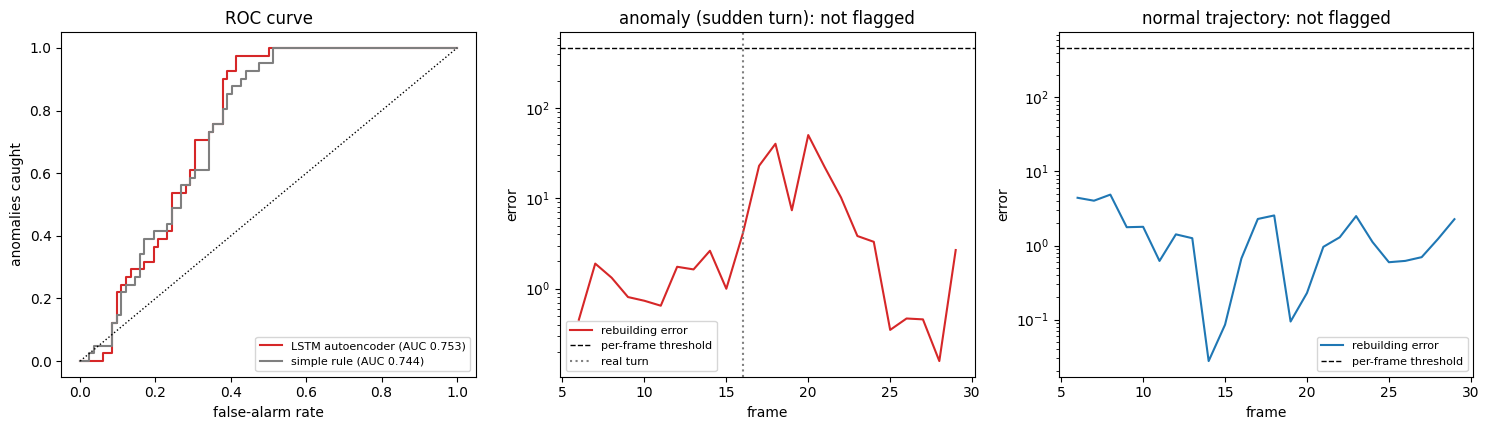

picture saved to C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module4_outputs\module4_results.png - use it on your slides


In [35]:
def roc_curve(s_norm, s_anom):
    ths = np.unique(np.concatenate([s_norm, s_anom]))
    ths = np.concatenate([[ths.max() + 1], ths[::-1]])
    return [(s_norm >= t).mean() for t in ths], [(s_anom >= t).mean() for t in ths]

fig = plt.figure(figsize=(15, 4.4))
ax = fig.add_subplot(1, 3, 1)
for name, a, b, col in [("LSTM autoencoder", sn, sa, "tab:red"), ("simple rule", rn, ra, "tab:gray")]:
    fpr, tpr = roc_curve(a, b)
    ax.plot(fpr, tpr, color=col, label=f"{name} (AUC {roc_auc(a, b):.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set_xlabel("false-alarm rate"); ax.set_ylabel("anomalies caught"); ax.set_title("ROC curve"); ax.legend(fontsize=8)

# a clearly detected anomaly and a typical normal trajectory
sa_all = seq_score(E_te_a)
i_a = int(np.argsort(sa_all)[len(sa_all) // 2])            # the median anomaly
i_n = int(np.argsort(sn)[len(sn) // 2])                    # the median normal
frames = np.arange(START + 1, START + 1 + X_te_a.shape[1])
for k, (E, meta, i, title, col) in enumerate([(E_te_a, te_a_meta, i_a, "anomaly (sudden turn)", "tab:red"),
                                              (E_te_n, te_n_meta, i_n, "normal trajectory", "tab:blue")]):
    ax = fig.add_subplot(1, 3, 2 + k)
    ax.plot(frames, E[i], col, label="rebuilding error")
    ax.axhline(STEP_THR, color="k", ls="--", lw=1, label="per-frame threshold")
    if meta[i]["t_maneuver"] is not None:
        ax.axvline(meta[i]["t_maneuver"], color="gray", ls=":", label="real turn")
    ax.set_yscale("log"); ax.set_xlabel("frame"); ax.set_ylabel("error")
    flag = "FLAGGED" if seq_score(E[i:i + 1])[0] > THRESHOLD else "not flagged"
    ax.set_title(f"{title}: {flag}"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(M4_DIR / "module4_results.png", dpi=130)
plt.show()
print("picture saved to", M4_DIR / "module4_results.png", "- use it on your slides")

In [36]:
def inject(vel, kind, t0, rng):
    v = np.array(vel, float)
    if kind == "speed_jump":
        v[t0:] *= rng.uniform(2.0, 3.0)
    elif kind == "reversal":
        v[t0:] *= -1.0
    elif kind == "drift":
        d = rng.choice([-1, 1]) * rng.uniform(0.12, 0.25)
        for t in range(t0, len(v)):
            a = (t - t0 + 1) * d
            c, s_ = np.cos(a), np.sin(a)
            v[t] = [c * v[t, 0] - s_ * v[t, 1], s_ * v[t, 0] + c * v[t, 1]]
    return v

rng = np.random.default_rng(1)
print(f"{'injected anomaly':18s} {'autoencoder AUC':>16s} {'caught at threshold':>20s} {'simple rule AUC':>16s}")
extra = {}
for kind in ["speed_jump", "reversal", "drift"]:
    feats = []
    for s in te_n_meta:
        t0 = int(rng.integers(10, 21))
        f = to_features(inject(s["vel"], kind, t0, rng))
        if f is not None:
            feats.append(f)
    Xk = np.stack(feats)
    sk = seq_score(step_errors(Xk))
    extra[kind] = dict(auc=roc_auc(sn, sk), recall=float((sk > THRESHOLD).mean()), rule_auc=roc_auc(rn, rule_score(Xk)))
    print(f"{kind:18s} {extra[kind]['auc']:16.3f} {100 * extra[kind]['recall']:19.0f}% {extra[kind]['rule_auc']:16.3f}")

injected anomaly    autoencoder AUC  caught at threshold  simple rule AUC
speed_jump                    0.864                  10%            0.918
reversal                      0.912                   9%            0.937
drift                         0.731                   5%            0.603


In [37]:
torch.save(ae_model.state_dict(), M4_DIR / "anomaly_lstm_ae.pt")
config = dict(tracker=TRACKER, start=START, smooth=SMOOTH, feature_names=FEATURE_NAMES,
              feat_mu=[float(v) for v in FEAT_MU], feat_sd=[float(v) for v in FEAT_SD], hidden=HIDDEN, latent=LATENT,
              score_mode=SCORE_MODE, thresh_pct=THRESH_PCT, threshold=THRESHOLD, step_threshold=STEP_THR,
              n_train=int(len(X_train)), n_val=int(len(X_val)), n_test_normal=int(len(X_te_n)),
              n_test_anomaly=int(len(X_te_a)), results=AE_RESULTS, injected=extra)
with open(M4_DIR / "module4_config.json", "w") as f:
    json.dump(config, f, indent=2)

def score_trajectory(vel_xy):
    """vel_xy: (T,2) velocity estimates in pixels/frame from Module 3 (T must match the training length).
    Returns dict(score, flag, step_errors), or None if the trajectory has gaps/NaNs."""
    f = to_features(np.asarray(vel_xy, float))
    if f is None:
        return None
    e = step_errors(f[None])[0]
    sc = float(seq_score(e[None])[0])
    return dict(score=sc, flag=bool(sc > THRESHOLD), step_errors=e)

# demo on one normal and one anomalous test trajectory
for name, meta in [("normal ", te_n_meta[0]), ("anomaly", te_a_meta[0])]:
    r = score_trajectory(meta["vel"])
    print(f"{name} -> anomaly score {r['score']:.4f} | flag: {'ANOMALY' if r['flag'] else 'normal'}")
print("\nsaved to folder:", M4_DIR)
for p in sorted(M4_DIR.iterdir()):
    print("  ", p.name)

normal  -> anomaly score 14.2499 | flag: normal
anomaly -> anomaly score 40.4960 | flag: normal

saved to folder: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module4_outputs
   anomaly_lstm_ae.pt
   module4_config.json
   module4_results.png


In [38]:
%pip install -q sgp4 requests pandas

Note: you may need to restart the kernel to use updated packages.


In [39]:
import os, re, json, time, math, hashlib, getpass
from pathlib import Path
from datetime import datetime, timezone, timedelta
from urllib.parse import quote
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

# ---- folders: reuse the ones from the earlier cells if they exist ----
try:
    WORK_DIR
except NameError:
    BASE_DIR = Path(r"C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A")
    WORK_DIR = BASE_DIR / "nova_work"
M5_DIR    = WORK_DIR / "module5_outputs"      # reports and pictures
CACHE_DIR = WORK_DIR / "module5_cache"        # saved Space-Track answers
M5_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ---- politeness settings (Space-Track limits: <30 requests/minute, <300/hour) ----
SATCAT_TTL_HOURS  = 24      # reuse a saved catalog answer for this long
GP_TTL_HOURS      = 1       # reuse saved orbital elements for this long
ALLOW_STALE_CACHE = True    # if the network or login fails, fall back to older saved answers (and say so)
MIN_SECONDS_BETWEEN_REQUESTS = 3.0
MAX_REQUESTS_PER_HOUR        = 100     # our own, stricter budget

# ---- how the verdicts are decided ----
LOW_CONF       = 0.60       # classifier confidence below this -> needs review
STALE_TLE_DAYS = 30         # orbital elements older than this are called stale
FINDINGS_LIMIT = 100         # how many pipeline findings to verify (Step 7)
N_VOTE_FRAMES  = 5          # frames used to vote on an object's class (Step 7)

print("Work folder :", WORK_DIR)
print("Output      :", M5_DIR)
print("Cache       :", CACHE_DIR)

Work folder : C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work
Output      : C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module5_outputs
Cache       : C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module5_cache


In [40]:
ST_USER = "kumartripti9911@gmail.com"
ST_PASS = "CZ.9xuhHw38QCw4"
if not ST_USER:
    ST_USER = input("Space-Track username/email (press Enter for DEMO mode): ").strip()
if ST_USER and not ST_PASS:
    ST_PASS = getpass.getpass("Space-Track password (hidden): ")

MODE = "live" if (ST_USER and ST_PASS) else "demo"
print("\nMODE =", MODE.upper())
if MODE == "demo":
    print("*** DEMO MODE: the catalog data used below is INVENTED. Do not report it as a result. ***")


MODE = LIVE


In [41]:
class RateLimiter:
    def __init__(self, min_gap=MIN_SECONDS_BETWEEN_REQUESTS, per_hour=MAX_REQUESTS_PER_HOUR):
        self.min_gap, self.per_hour, self.stamps = min_gap, per_hour, []
    def wait(self):
        now = time.time()
        self.stamps = [t for t in self.stamps if now - t < 3600]
        if len(self.stamps) >= self.per_hour:
            raise RuntimeError(f"Our own hourly budget of {self.per_hour} requests is used up. Wait, or re-run later.")
        if self.stamps and now - self.stamps[-1] < self.min_gap:
            time.sleep(self.min_gap - (now - self.stamps[-1]))
        self.stamps.append(time.time())

class DiskCache:
    def __init__(self, folder):
        self.folder = Path(folder)
    def _path(self, url):
        return self.folder / (hashlib.sha1(url.encode("utf-8")).hexdigest()[:20] + ".json")
    def get(self, url, ttl_hours, allow_stale=False):
        p = self._path(url)
        if not p.exists():
            return None
        d = json.loads(p.read_text(encoding="utf-8"))
        age_h = (time.time() - d["fetched_at"]) / 3600
        return (d["data"], age_h) if (age_h <= ttl_hours or allow_stale) else None
    def put(self, url, data):
        self._path(url).write_text(json.dumps(dict(url=url, fetched_at=time.time(), data=data)), encoding="utf-8")

class SpaceTrackClient:
    mode = "live"
    BASE = "https://www.space-track.org"
    def __init__(self, user, password, cache, limiter, session=None):
        self.user, self.password, self.cache, self.limiter = user, password, cache, limiter
        self.s = session or requests.Session()
        self.logged_in = False
        self.log = []                                   # what was fetched live and what came from the cache

    def login(self):
        self.limiter.wait()
        r = self.s.post(f"{self.BASE}/ajaxauth/login", data={"identity": self.user, "password": self.password}, timeout=30)
        if r.status_code != 200 or "Failed" in r.text[:300]:
            raise RuntimeError("Space-Track login failed. Check the username (your email) and password.")
        self.logged_in = True

    def _fetch(self, url, ttl):
        hit = self.cache.get(url, ttl)
        if hit:
            self.log.append(("cache", url, f"{hit[1]:.1f} h old"))
            return hit[0]
        try:
            if not self.logged_in:
                self.login()
            for attempt in (1, 2):
                self.limiter.wait()
                r = self.s.get(url, timeout=60)
                if r.status_code == 401 and attempt == 1:       # session expired: log in again once
                    self.logged_in = False
                    self.login()
                    continue
                if r.status_code == 429:
                    raise RuntimeError("Space-Track says too many requests (HTTP 429). Wait a few minutes and re-run; saved answers are reused.")
                r.raise_for_status()
                data = r.json()
                break
            self.cache.put(url, data)
            self.log.append(("fetched live", url, ""))
            return data
        except Exception as e:
            stale = self.cache.get(url, ttl, allow_stale=True) if ALLOW_STALE_CACHE else None
            if stale:
                self.log.append(("STALE cache", url, f"{stale[1]:.1f} h old, because: {type(e).__name__}"))
                return stale[0]
            raise

    def satcat_by_name(self, text):
        """Catalog entries whose name CONTAINS `text` (Space-Track's ~~ operator)."""
        url = f"{self.BASE}/basicspacedata/query/class/satcat/SATNAME/~~{quote(text, safe='-')}/format/json"
        return self._fetch(url, SATCAT_TTL_HOURS)

    def gp_by_ids(self, ids):
        """Current orbital elements for several catalog numbers in ONE request."""
        ids = ",".join(sorted({str(i) for i in ids}))
        url = f"{self.BASE}/basicspacedata/query/class/gp/NORAD_CAT_ID/{ids}/format/json"
        return self._fetch(url, GP_TTL_HOURS)

# ------------------------------------------------------------------ invented data for DEMO mode
MU_EARTH, R_EARTH = 398600.4418, 6378.137

def derive_orbit(mean_motion, ecc):
    n = mean_motion * 2 * math.pi / 86400.0
    a = (MU_EARTH / n ** 2) ** (1 / 3)
    return dict(PERIOD=1440.0 / mean_motion, SEMIMAJOR_AXIS=a, PERIGEE=a * (1 - ecc) - R_EARTH, APOGEE=a * (1 + ecc) - R_EARTH)

def make_demo_data():
    epoch = (datetime.now(timezone.utc) - timedelta(hours=12)).strftime("%Y-%m-%dT%H:%M:%S.%f")
    # name, fake id, type, country, launch, decay, has elements, inclination, mean motion (rev/day), eccentricity
    specs = [("CHEOPS",               990001, "PAYLOAD", "ESA", "2000-01-01", None,         True,  98.2, 14.8, 0.0012),
             ("XMM-NEWTON",           990002, "PAYLOAD", "ESA", "2000-01-01", None,         True,  70.0,  2.0, 0.70),
             ("PROBA-2",              990003, "PAYLOAD", "ESA", "2000-01-01", None,         True,  98.3, 14.5, 0.0010),
             ("PROBA-3 CSC",          990004, "PAYLOAD", "ESA", "2000-01-02", None,         True,  59.0,  2.0, 0.60),
             ("PROBA-3 OSC",          990005, "PAYLOAD", "ESA", "2000-01-02", None,         True,  59.0,  2.0, 0.61),
             ("SMART-1",              990006, "PAYLOAD", "ESA", "2000-01-01", "2000-01-02", False, 0, 0, 0),
             ("SOHO",                 990007, "PAYLOAD", "ESA", "2000-01-01", None,         False, 0, 0, 0),
             ("DOUBLE STAR 1 (TC-1)", 990008, "PAYLOAD", "PRC", "2000-01-03", None,         True,  28.5,  4.0, 0.50),
             ("DOUBLE STAR 2 (TC-2)", 990009, "PAYLOAD", "PRC", "2000-01-03", None,         True,  90.0,  4.0, 0.50)]
    satcat, gp = [], []
    for name, nid, otype, country, launch, decay, has_gp, inc, mm, ecc in specs:
        satcat.append(dict(NORAD_CAT_ID=str(nid), SATNAME=f"{name} (DEMO)", OBJECT_TYPE=otype, COUNTRY=country,
                           LAUNCH=launch, DECAY=decay, DEMO=True))
        if has_gp:
            row = dict(OBJECT_NAME=f"{name} (DEMO)", OBJECT_ID="0000-000A", NORAD_CAT_ID=str(nid), OBJECT_TYPE=otype,
                       CLASSIFICATION_TYPE="U", EPHEMERIS_TYPE="0", ELEMENT_SET_NO="999", REV_AT_EPOCH="100",
                       EPOCH=epoch, MEAN_MOTION=str(mm), ECCENTRICITY=str(ecc), INCLINATION=str(inc),
                       RA_OF_ASC_NODE="120.0", ARG_OF_PERICENTER="90.0", MEAN_ANOMALY="10.0", BSTAR="0.00002",
                       MEAN_MOTION_DOT="0.00001", MEAN_MOTION_DDOT="0", DECAY_DATE=None, DEMO=True)
            row.update({k: str(v) for k, v in derive_orbit(mm, ecc).items()})
            gp.append(row)
    return satcat, gp

class DemoClient:
    """Offline stand-in with INVENTED data. Lets the notebook run without an account. Never report its output as a result."""
    mode = "demo"
    def __init__(self):
        self.satcat, self.gp = make_demo_data()
        self.log = [("DEMO", "built-in invented fixture", "no network used")]
    def satcat_by_name(self, text):
        return [r for r in self.satcat if text.upper() in r["SATNAME"].upper()]
    def gp_by_ids(self, ids):
        ids = {str(i) for i in ids}
        return [r for r in self.gp if r["NORAD_CAT_ID"] in ids]

def make_client():
    if MODE == "demo":
        return DemoClient()
    return SpaceTrackClient(ST_USER, ST_PASS, DiskCache(CACHE_DIR), RateLimiter())

client = make_client()
print("client ready:", client.mode.upper())

client ready: LIVE


In [42]:
CLASS_TO_CATALOG = {
    "cheops":          dict(queries=["CHEOPS"],               pattern=r"CHEOPS"),
    "xmm_newton":      dict(queries=["XMM"],                  pattern=r"XMM"),
    "proba_2":         dict(queries=["PROBA"],                pattern=r"PROBA[\s\-_]*2\b"),
    "proba_3_csc":     dict(queries=["PROBA"],                pattern=r"PROBA[\s\-_]*3.*(CSC|CORONAGRAPH)", family=r"PROBA[\s\-_]*3"),
    "proba_3_ocs":     dict(queries=["PROBA"],                pattern=r"PROBA[\s\-_]*3.*(OCS|OSC|OCCULTER)", family=r"PROBA[\s\-_]*3"),
    "smart_1":         dict(queries=["SMART-1", "SMART 1"],   pattern=r"SMART[\s\-_]*1\b"),
    "lisa_pathfinder": dict(queries=["LISA"],                 pattern=r"LISA"),
    "soho":            dict(queries=["SOHO"],                 pattern=r"\bSOHO\b"),
    "double_star":     dict(queries=["DOUBLE STAR"],          pattern=r"DOUBLE[\s\-_]*STAR"),
    "debris":                    None,    # a category, not one object
    "earth_observation_sat_1":   None,    # a generic model in SPARK; edit if you know the real satellite it represents
}

def row_name(r):
    return (r.get("SATNAME") or r.get("OBJECT_NAME") or "").strip()

def has_decayed(r):
    d = str(r.get("DECAY") or "").strip().lower()
    return d not in ("", "none", "null")

def lookup_class(cls, cfg):
    for q in cfg["queries"]:
        rows = client.satcat_by_name(q)
        found = [r for r in rows if re.search(cfg["pattern"], row_name(r), re.I)]
        family = False
        if not found and cfg.get("family"):
            found = [r for r in rows if re.search(cfg["family"], row_name(r), re.I)]
            family = bool(found)
        if found:
            found.sort(key=lambda r: (has_decayed(r), -int(str(r.get("LAUNCH") or "0000-00-00").replace("-", "")[:8] or 0)))
            r0 = found[0]
            return dict(cls=cls, matched=True, query=q, name=row_name(r0), norad=int(r0["NORAD_CAT_ID"]),
                        object_type=r0.get("OBJECT_TYPE"), country=r0.get("COUNTRY"), launch=r0.get("LAUNCH"),
                        decay=(str(r0["DECAY"]) if has_decayed(r0) else None), n_candidates=len(found),
                        candidates=[row_name(r) for r in found], ambiguous=len({r["NORAD_CAT_ID"] for r in found}) > 1,
                        family_match=family, demo=bool(r0.get("DEMO")))
    return dict(cls=cls, matched=False, queries_tried=cfg["queries"])

cards = {}
for cls, cfg in CLASS_TO_CATALOG.items():
    cards[cls] = None if cfg is None else lookup_class(cls, cfg)

rows = []
for cls, c in cards.items():
    if c is None:
        rows.append(dict(cls=cls, catalog_name="(generic class)", norad="", type="", country="", launch="", decay="", candidates=""))
    elif not c["matched"]:
        rows.append(dict(cls=cls, catalog_name="NOT FOUND", norad="", type="", country="", launch="", decay="", candidates=""))
    else:
        note = (" [family match]" if c["family_match"] else "") + (" [AMBIGUOUS]" if c["ambiguous"] else "")
        rows.append(dict(cls=cls, catalog_name=c["name"] + note, norad=c["norad"], type=c["object_type"], country=c["country"],
                         launch=c["launch"], decay=c["decay"] or "", candidates=c["n_candidates"]))
lookup_table = pd.DataFrame(rows)
display(lookup_table)
print("\nCheck each row: is that really the right object for the class? Edit CLASS_TO_CATALOG above and re-run if not.")

,cls,catalog_name,norad,type,country,launch,decay,candidates
0,cheops,CHEOPS,44874,PAYLOAD,ESA,2019-12-18,,1
1,xmm_newton,XMM,25989,PAYLOAD,ESA,1999-12-10,,1
2,proba_2,PROBA 2,36037,PAYLOAD,ESA,2009-11-02,,1
3,proba_3_csc,PROBA-3 CSC,62256,PAYLOAD,ESA,2024-12-05,,1
4,proba_3_ocs,PROBA-3 OSC,62258,PAYLOAD,ESA,2024-12-05,,1
5,smart_1,SMART 1,27949,PAYLOAD,ESA,2003-09-27,2006-09-03,1
6,lisa_pathfinder,PALISADE [AMBIGUOUS],44634,PAYLOAD,US,2019-10-17,,9
7,soho,SOHO,23726,PAYLOAD,ESA,1995-12-02,,1
8,double_star,NOT FOUND,,,,,,
9,debris,(generic class),,,,,,



Check each row: is that really the right object for the class? Edit CLASS_TO_CATALOG above and re-run if not.


In [43]:
from sgp4.api import Satrec, jday, WGS72
from sgp4 import omm as sgp4_omm

def parse_epoch(text):
    t = str(text).replace(" ", "T")
    if "." not in t:
        t += ".000000"
    return datetime.strptime(t[:26], "%Y-%m-%dT%H:%M:%S.%f").replace(tzinfo=timezone.utc)

def satrec_from_gp(row):
    """Build an SGP4 satellite object from a Space-Track GP record (uses the TLE lines if present, else the OMM fields)."""
    l1, l2 = row.get("TLE_LINE1"), row.get("TLE_LINE2")
    if l1 and l2:
        return Satrec.twoline2rv(l1, l2)
    f = dict(row)
    f["EPOCH"] = parse_epoch(f["EPOCH"]).strftime("%Y-%m-%dT%H:%M:%S.%f")
    f["CLASSIFICATION_TYPE"] = f.get("CLASSIFICATION_TYPE") or "U"
    f["EPHEMERIS_TYPE"]      = f.get("EPHEMERIS_TYPE") or "0"
    f["ELEMENT_SET_NO"]      = f.get("ELEMENT_SET_NO") or "999"
    f["REV_AT_EPOCH"]        = f.get("REV_AT_EPOCH") or "0"
    f["OBJECT_ID"]           = f.get("OBJECT_ID") or "0000-000A"
    sat = Satrec()
    sgp4_omm.initialize(sat, f)
    return sat

def propagate(sat, when):
    jd, fr = jday(when.year, when.month, when.day, when.hour, when.minute, when.second + when.microsecond * 1e-6)
    err, r, v = sat.sgp4(jd, fr)
    return err, np.array(r, float), np.array(v, float)

def orbit_regime(perigee, apogee, ecc):
    if perigee is None or apogee is None:
        return "unknown"
    if ecc is not None and ecc > 0.25:
        return "HEO (highly elliptical)"
    if apogee < 2000:
        return "LEO"
    if perigee > 34000 and apogee < 37000:
        return "GEO"
    if apogee < 34000:
        return "MEO"
    return "high orbit"

def fnum(row, key):
    try:
        return float(row[key])
    except (KeyError, TypeError, ValueError):
        return None

NOW = datetime.now(timezone.utc)
SATRECS = {}                                                          # norad id -> SGP4 object (used for ground tracks)
ids = [c["norad"] for c in cards.values() if c and c["matched"] and not c["decay"]]
gp_rows = client.gp_by_ids(ids) if ids else []
gp_by_id = {int(r["NORAD_CAT_ID"]): r for r in gp_rows}
print(f"orbital elements received for {len(gp_by_id)} of {len(ids)} objects")

for cls, c in cards.items():
    if not c or not c["matched"]:
        continue
    c["gp_ok"] = False
    g = gp_by_id.get(c["norad"])
    if g is None:
        continue
    try:
        sat = satrec_from_gp(g)
        err, r, v = propagate(sat, NOW)
        ecc = fnum(g, "ECCENTRICITY"); mm = fnum(g, "MEAN_MOTION")
        derived = derive_orbit(mm, ecc) if (mm and ecc is not None) else {}
        period  = fnum(g, "PERIOD")  or derived.get("PERIOD")
        perigee = fnum(g, "PERIGEE") if fnum(g, "PERIGEE") is not None else derived.get("PERIGEE")
        apogee  = fnum(g, "APOGEE")  if fnum(g, "APOGEE")  is not None else derived.get("APOGEE")
        epoch = parse_epoch(g["EPOCH"])
        c.update(gp_ok=(err == 0), epoch=epoch.isoformat(timespec="seconds"), tle_age_days=(NOW - epoch).total_seconds() / 86400,
                 period_min=period, perigee_km=perigee, apogee_km=apogee, inclination_deg=fnum(g, "INCLINATION"), ecc=ecc,
                 regime=orbit_regime(perigee, apogee, ecc),
                 alt_now_km=float(np.linalg.norm(r) - R_EARTH) if err == 0 else None,
                 speed_now_kms=float(np.linalg.norm(v)) if err == 0 else None)
        if err == 0:
            SATRECS[c["norad"]] = sat
    except Exception as e:
        c["gp_error"] = f"{type(e).__name__}: {e}"

rows = []
for cls, c in cards.items():
    if c and c["matched"]:
        rows.append(dict(cls=cls, catalog_name=c["name"], regime=c.get("regime", ""), period_min=c.get("period_min"),
                         perigee_km=c.get("perigee_km"), apogee_km=c.get("apogee_km"), inclination=c.get("inclination_deg"),
                         elements_age_days=c.get("tle_age_days"), alt_now_km=c.get("alt_now_km"), speed_now_kms=c.get("speed_now_kms")))
orbit_table = pd.DataFrame(rows).round(2)
display(orbit_table)

orbital elements received for 6 of 7 objects


,cls,catalog_name,regime,period_min,perigee_km,apogee_km,inclination,elements_age_days,alt_now_km,speed_now_kms
0,cheops,CHEOPS,LEO,98.49,678.27,695.00,98.15,0.35,677.92,7.52
1,xmm_newton,XMM,HEO (highly elliptical),2872.65,29483.87,91638.67,63.87,0.56,77659.47,1.88
2,proba_2,PROBA 2,LEO,98.98,701.15,718.20,98.25,0.30,711.90,7.49
3,proba_3_csc,PROBA-3 CSC,HEO (highly elliptical),1179.57,1035.35,60170.11,59.84,1.34,42261.37,2.37
4,proba_3_ocs,PROBA-3 OSC,HEO (highly elliptical),1179.57,1035.53,60169.87,59.84,1.34,42258.30,2.37
5,smart_1,SMART 1,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,lisa_pathfinder,PALISADE,LEO,109.76,1207.38,1224.17,87.88,0.64,1202.83,7.25
7,soho,SOHO,,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [44]:
def missing_pipeline_pieces():
    needed = ["test_seqs", "test_recs", "shift_image", "box_center_wh", "model", "eval_tf", "class_names",
              "run_tracker", "KalmanCV", "kf_params", "score_trajectory"]
    return [n for n in needed if n not in globals()]

def build_findings_from_pipeline(limit):
    import torch
    from PIL import Image
    try:
        from tqdm.auto import tqdm
    except ImportError:
        tqdm = lambda x, **k: x
    rec_by_name = {r["filename"]: r for r in list(globals().get("dev_recs", [])) + list(test_recs)}
    cls_device = next(model.parameters()).device

    def found_fraction(s):
        det = s["det_full"] if "det_full" in s else s["det"]
        return float((~np.isnan(det[:, 0])).mean())

    usable = [s for s in test_seqs if found_fraction(s) >= 0.2]          # sequences where the detector found the object
    order = np.random.default_rng(0).permutation(len(usable))[:limit]
    findings = []
    model.eval()
    for i in tqdm(order):
        s = usable[i]
        rec = rec_by_name[s["id"].rsplit("_", 1)[0]]
        img = np.array(Image.open(rec["path"]).convert("RGB"))
        det = s["det_full"] if "det_full" in s else s["det"]
        c0, _, _ = box_center_wh(rec["bbox"])
        ok = np.where(~np.isnan(det[:, 0]))[0]
        best = ok[np.argsort(-det[ok, 4])[:N_VOTE_FRAMES]]                  # frames where the detector was most confident
        probs = []
        with torch.no_grad():
            for t in best:
            # same crop recipe as Module 2: the detected box plus 10% padding, clipped to the 640x640 frame
                dx, dy = np.round(s["true_xy"][t] - c0).astype(int)
                frame = shift_image(img, int(dx), int(dy))
                cx, cy, w, h = det[t, :4]
                x1, y1 = max(0, cx - w / 2 - 0.10 * w), max(0, cy - h / 2 - 0.10 * h)
                x2, y2 = min(640, cx + w / 2 + 0.10 * w), min(640, cy + h / 2 + 0.10 * h)
                crop = Image.fromarray(frame).crop((int(x1), int(y1), int(x2), int(y2)))
                logits = model(eval_tf(crop).unsqueeze(0).to(cls_device))
                probs.append(torch.softmax(logits, dim=1)[0].cpu().numpy())
        p = np.mean(probs, axis=0)
        _, kf_v = run_tracker(s["det"][:, :2], KalmanCV(**kf_params))      # Module 3
        res = score_trajectory(kf_v)                                        # Module 4 (None if the track has gaps)
        findings.append(dict(id=s["id"], kind=s["kind"], true_class=rec["class"],
                             pred_class=class_names[int(p.argmax())], class_conf=float(p.max()),
                             anomaly_score=None if res is None else res["score"],
                             anomaly_flag=None if res is None else bool(res["flag"]),
                             speed_px_per_frame=float(np.nanmedian(np.hypot(kf_v[:, 0], kf_v[:, 1]))),
                             source="pipeline (Modules 1-4)"))
    return findings

def findings_from_labels(limit):
    recs = list(globals().get("test_recs", []))
    order = np.random.default_rng(0).permutation(len(recs))[:limit]
    return [dict(id=recs[i]["filename"], kind=None, true_class=recs[i]["class"], pred_class=recs[i]["class"], class_conf=1.0,
                 anomaly_score=None, anomaly_flag=None, speed_px_per_frame=None, source="ground-truth label") for i in order]

missing = missing_pipeline_pieces()
if missing:
    raise RuntimeError(
        "Module 5 must run in the SAME kernel session as Modules 1-4 (no restart in between).\n"
        f"Missing objects: {missing}\n"
        "Fix: Kernel > Restart & Run All, or run the cells above first.")
if type(model).__name__ != "EfficientNet":
    raise RuntimeError("`model` is not the classifier (the detector-evaluation cell overwrote it). "
                       "Re-run the classifier load + evaluate cells, then this cell.")

findings = build_findings_from_pipeline(FINDINGS_LIMIT)
assert findings and all(f["source"].startswith("pipeline") for f in findings)

print(f"{len(findings)} findings from: {findings[0]['source']}")
print(f"{sum(f['anomaly_score'] is not None for f in findings)} of {len(findings)} have an anomaly score from Module 4")
display(pd.DataFrame(findings).head(8))

  0%|          | 0/100 [00:00<?, ?it/s]

100 findings from: pipeline (Modules 1-4)
97 of 100 have an anomaly score from Module 4


,id,kind,true_class,pred_class,class_conf,anomaly_score,anomaly_flag,speed_px_per_frame,source
0,img095610.jpg_maneuver,maneuver,soho,soho,0.839215,1.494390,False,3.926410,pipeline (Modules 1-4)
1,img102578.jpg_curved,curved,xmm_newton,xmm_newton,0.914336,0.837719,False,2.114512,pipeline (Modules 1-4)
2,img067386.jpg_curved,curved,proba_3_csc,proba_3_csc,0.675943,13.891938,False,7.030044,pipeline (Modules 1-4)
3,img109248.jpg_linear,linear,xmm_newton,earth_observation_sat_1,0.822054,15.577653,False,4.982953,pipeline (Modules 1-4)
4,img055010.jpg_linear,linear,lisa_pathfinder,lisa_pathfinder,0.540049,0.930092,False,7.251229,pipeline (Modules 1-4)
5,img067386.jpg_linear,linear,proba_3_csc,proba_3_csc,0.908207,15.922193,False,3.793761,pipeline (Modules 1-4)
6,img085665.jpg_curved,curved,smart_1,smart_1,0.486213,0.723664,False,7.887350,pipeline (Modules 1-4)
7,img070764.jpg_curved,curved,proba_3_ocs,proba_3_ocs,0.931572,144.752182,True,5.266120,pipeline (Modules 1-4)


,id,kind,true_class,pred_class,class_conf,catalog_name,norad_id,object_type,catalog_status,verdict,alert,notes
0,img095610.jpg_maneuver,maneuver,soho,soho,0.84,SOHO,23726,PAYLOAD,IN_CATALOG_NO_ORBIT_DATA,UNVERIFIABLE,False,listed in the catalog but no current orbital elements
1,img102578.jpg_curved,curved,xmm_newton,xmm_newton,0.91,XMM,25989,PAYLOAD,VERIFIED_IN_ORBIT,CONFIRMED,False,
2,img067386.jpg_curved,curved,proba_3_csc,proba_3_csc,0.68,PROBA-3 CSC,62256,PAYLOAD,VERIFIED_IN_ORBIT,CONFIRMED,False,
3,img109248.jpg_linear,linear,xmm_newton,earth_observation_sat_1,0.82,,,,GENERIC_CLASS,UNVERIFIABLE,False,no single catalog object for this class
4,img055010.jpg_linear,linear,lisa_pathfinder,lisa_pathfinder,0.54,PALISADE,44634,PAYLOAD,VERIFIED_IN_ORBIT,NEEDS_REVIEW,False,several catalog objects match this name: PALISADE; LISA PATHFINDER...
5,img067386.jpg_linear,linear,proba_3_csc,proba_3_csc,0.91,PROBA-3 CSC,62256,PAYLOAD,VERIFIED_IN_ORBIT,CONFIRMED,False,
6,img085665.jpg_curved,curved,smart_1,smart_1,0.49,SMART 1,27949,PAYLOAD,DECAYED,NEEDS_REVIEW,False,catalog says it re-entered on 2006-09-03; classifier confidence on...
7,img070764.jpg_curved,curved,proba_3_ocs,proba_3_ocs,0.93,PROBA-3 OSC,62258,PAYLOAD,VERIFIED_IN_ORBIT,CONFIRMED,True,sudden turn is plausible for an active satellite
8,img006006.jpg_maneuver,maneuver,proba_2,proba_2,0.71,PROBA 2,36037,PAYLOAD,VERIFIED_IN_ORBIT,CONFIRMED,False,
9,img079304.jpg_linear,linear,proba_3_ocs,proba_3_ocs,0.94,PROBA-3 OSC,62258,PAYLOAD,VERIFIED_IN_ORBIT,CONFIRMED,False,



verdicts:        {'UNVERIFIABLE': 36, 'CONFIRMED': 35, 'NEEDS_REVIEW': 29}
catalog status:  {'VERIFIED_IN_ORBIT': 54, 'GENERIC_CLASS': 20, 'IN_CATALOG_NO_ORBIT_DATA': 13, 'NOT_IN_CATALOG': 8, 'DECAYED': 5}
alerts (unusual motion flagged by Module 4): 5
classifier agreed with the dataset label on 85% of these findings


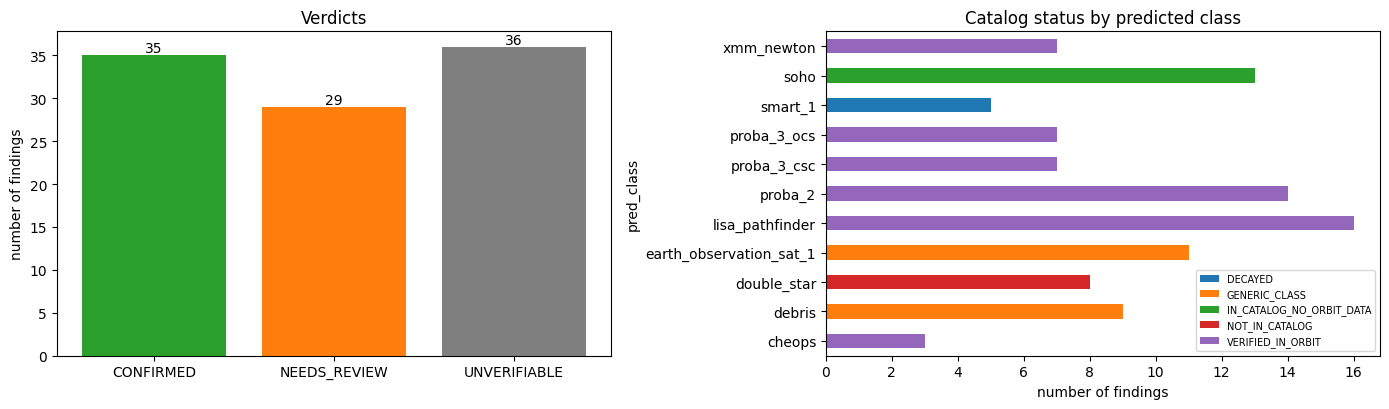

In [45]:
NON_MANEUVERING = {"DEBRIS", "ROCKET BODY"}

def verify_finding(f):
    cls, notes, conflicts = f["pred_class"], [], []
    card = cards.get(cls, "unknown")
    if card == "unknown":
        status = "UNKNOWN_CLASS"
    elif card is None:
        status = "GENERIC_CLASS"
        notes.append("no single catalog object for this class")
    elif not card["matched"]:
        status = "NOT_IN_CATALOG"
        notes.append("no catalog entry matched the name search")
    elif card["decay"]:
        status = "DECAYED"
        conflicts.append(f"catalog says it re-entered on {card['decay']}")
    elif card.get("gp_ok"):
        status = "VERIFIED_IN_ORBIT"
    else:
        status = "IN_CATALOG_NO_ORBIT_DATA"
        notes.append("listed in the catalog but no current orbital elements")

    if card not in (None, "unknown") and card.get("matched"):
        if card.get("ambiguous"):
            conflicts.append("several catalog objects match this name: " + "; ".join(card["candidates"][:3]))
        if card.get("family_match"):
            notes.append("matched the mission family, not the exact spacecraft")
        if card.get("tle_age_days") is not None and card["tle_age_days"] > STALE_TLE_DAYS:
            conflicts.append(f"orbital elements are {card['tle_age_days']:.0f} days old")
    if f["class_conf"] < LOW_CONF:
        conflicts.append(f"classifier confidence only {f['class_conf']:.2f}")

    if f.get("anomaly_flag"):
        otype = (card or {}).get("object_type") if isinstance(card, dict) and card.get("matched") else None
        if cls == "debris" or (otype or "").upper() in NON_MANEUVERING:
            conflicts.append("sudden turn on a debris-like object: debris cannot manoeuvre, so the class or the track is suspect")
        elif status == "VERIFIED_IN_ORBIT":
            notes.append("sudden turn is plausible for an active satellite")

    if conflicts:
        verdict = "NEEDS_REVIEW"
    elif status == "VERIFIED_IN_ORBIT":
        verdict = "CONFIRMED"
    else:
        verdict = "UNVERIFIABLE"
    ok_card = isinstance(card, dict) and card.get("matched")
    return dict(id=f["id"], kind=f.get("kind"), true_class=f.get("true_class"), pred_class=cls, class_conf=round(f["class_conf"], 2),
                catalog_name=card["name"] if ok_card else "", norad_id=card["norad"] if ok_card else "",
                object_type=(card.get("object_type") or "") if ok_card else "", catalog_status=status, verdict=verdict,
                alert=bool(f.get("anomaly_flag")), notes="; ".join(conflicts + notes),
                data_source=("DEMO" if client.mode == "demo" else "Space-Track") + " | " + f["source"])

report = pd.DataFrame([verify_finding(f) for f in findings])
display(report.drop(columns=["data_source"]).head(15))

print("\nverdicts:       ", report["verdict"].value_counts().to_dict())
print("catalog status: ", report["catalog_status"].value_counts().to_dict())
print("alerts (unusual motion flagged by Module 4):", int(report["alert"].sum()))
if report["true_class"].notna().all() and len(report):
    print(f"classifier agreed with the dataset label on {100 * np.mean(report['pred_class'] == report['true_class']):.0f}% of these findings")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
vc = report["verdict"].value_counts().reindex(["CONFIRMED", "NEEDS_REVIEW", "UNVERIFIABLE"]).fillna(0)
axes[0].bar(vc.index, vc.values, color=["tab:green", "tab:orange", "tab:gray"])
axes[0].set_title("Verdicts"); axes[0].set_ylabel("number of findings")
for x, v in enumerate(vc.values):
    axes[0].text(x, v, int(v), ha="center", va="bottom")
by_cls = report.groupby(["pred_class", "catalog_status"]).size().unstack(fill_value=0)
by_cls.plot(kind="barh", stacked=True, ax=axes[1])
axes[1].set_title("Catalog status by predicted class"); axes[1].set_xlabel("number of findings"); axes[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(M5_DIR / ("module5_results" + ("_DEMO" if client.mode == "demo" else "") + ".png"), dpi=130)
plt.show()

In [46]:
tag = "_DEMO" if client.mode == "demo" else ""
report.to_csv(M5_DIR / f"verification_report{tag}.csv", index=False, encoding="utf-8-sig")
lookup_table.to_csv(M5_DIR / f"catalog_lookup{tag}.csv", index=False, encoding="utf-8-sig")
orbit_table.to_csv(M5_DIR / f"orbit_table{tag}.csv", index=False, encoding="utf-8-sig")

summary = dict(mode=client.mode, run_at_utc=NOW.isoformat(timespec="seconds"), n_findings=len(report),
               verdicts=report["verdict"].value_counts().to_dict(), catalog_status=report["catalog_status"].value_counts().to_dict(),
               alerts=int(report["alert"].sum()), findings_source=findings[0]["source"] if findings else None,
               class_to_catalog={k: (v if v is None else v["queries"] if "queries" in v else v) for k, v in CLASS_TO_CATALOG.items()},
               requests=[dict(how=h, url=u, note=n) for h, u, n in client.log])
(M5_DIR / f"module5_config{tag}.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")

print("saved to:", M5_DIR)
for p in sorted(M5_DIR.iterdir()):
    print("  ", p.name)
print("\nrequests made / served from cache:")
for how, url, note in client.log:
    print(f"  {how:13s} {url.replace('https://www.space-track.org', '')[:90]} {note}")

saved to: C:\Users\kumar\Downloads\College\Minor\Project N.O.V.A\nova_work\module5_outputs
   catalog_lookup.csv
   ground_tracks.png
   module5_config.json
   module5_results.png
   orbit_table.csv
   verification_report.csv

requests made / served from cache:
  cache         /basicspacedata/query/class/satcat/SATNAME/~~CHEOPS/format/json 1.0 h old
  cache         /basicspacedata/query/class/satcat/SATNAME/~~XMM/format/json 1.0 h old
  cache         /basicspacedata/query/class/satcat/SATNAME/~~PROBA/format/json 1.0 h old
  cache         /basicspacedata/query/class/satcat/SATNAME/~~PROBA/format/json 1.0 h old
  cache         /basicspacedata/query/class/satcat/SATNAME/~~PROBA/format/json 1.0 h old
  cache         /basicspacedata/query/class/satcat/SATNAME/~~SMART-1/format/json 1.0 h old
  cache         /basicspacedata/query/class/satcat/SATNAME/~~SMART%201/format/json 1.0 h old
  cache         /basicspacedata/query/class/satcat/SATNAME/~~LISA/format/json 1.0 h old
  cache         /basic

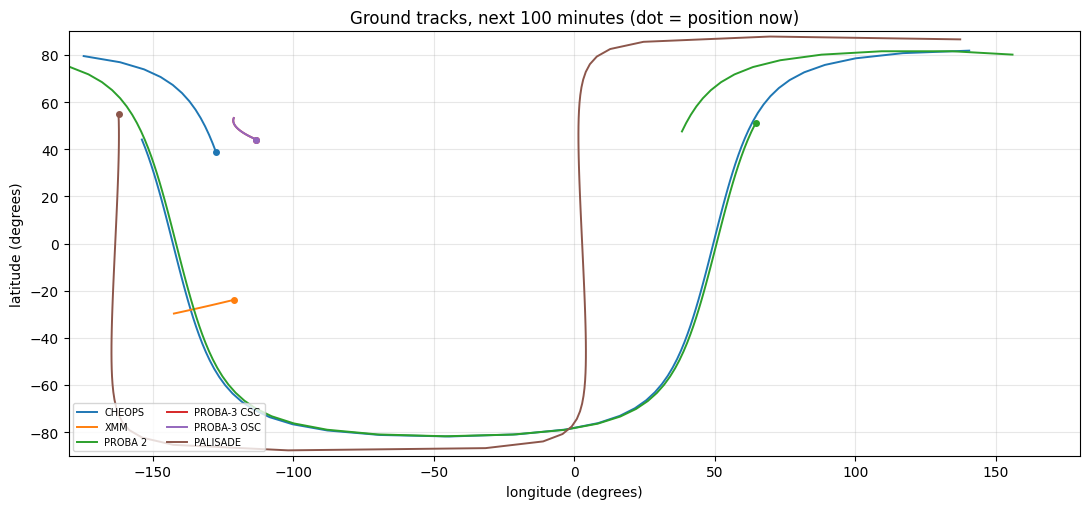

In [47]:
def gmst_rad(jd, fr):
    t = ((jd - 2451545.0) + fr) / 36525.0
    sec = 67310.54841 + (876600 * 3600 + 8640184.812866) * t + 0.093104 * t ** 2 - 6.2e-6 * t ** 3
    return math.radians((sec / 240.0) % 360.0)

def ground_track(sat, start, minutes=100):
    lats, lons = [], []
    for m in range(minutes + 1):
        when = start + timedelta(minutes=m)
        jd, fr = jday(when.year, when.month, when.day, when.hour, when.minute, when.second)
        err, r, _ = sat.sgp4(jd, fr)
        if err != 0:
            lats.append(np.nan); lons.append(np.nan); continue
        g = gmst_rad(jd, fr)
        x, y, z = r[0] * math.cos(g) + r[1] * math.sin(g), -r[0] * math.sin(g) + r[1] * math.cos(g), r[2]
        lats.append(math.degrees(math.asin(z / math.sqrt(x * x + y * y + z * z))))
        lons.append(math.degrees(math.atan2(y, x)))
    lons = np.array(lons)
    jump = np.where(np.abs(np.diff(lons)) > 180)[0]                 # break the line where it wraps around the map edge
    lons[jump + 1] = np.nan
    return np.array(lons), np.array(lats)

fig, ax = plt.subplots(figsize=(11, 5.2))
for cls, c in cards.items():
    if c and c["matched"] and c["norad"] in SATRECS:
        lon, lat = ground_track(SATRECS[c["norad"]], NOW)
        ax.plot(lon, lat, lw=1.4, label=c["name"])
        ax.plot(lon[0], lat[0], "o", ms=4, color=ax.lines[-1].get_color())
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.grid(alpha=0.3)
ax.set_xlabel("longitude (degrees)"); ax.set_ylabel("latitude (degrees)")
ax.set_title("Ground tracks, next 100 minutes (dot = position now)" + ("   [DEMO DATA]" if client.mode == "demo" else ""))
if SATRECS:
    ax.legend(fontsize=7, loc="lower left", ncol=2)
plt.tight_layout()
plt.savefig(M5_DIR / ("ground_tracks" + ("_DEMO" if client.mode == "demo" else "") + ".png"), dpi=130)
plt.show()